<a href="https://colab.research.google.com/github/dbbitz/inferencia/blob/main/Trabalho_Final_Primeira_Entrega.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Trabalho final — 1ª entrega

**Disciplina:** Inferência e Análise de Regressão

Professora Luzia Pedroso de Oliveira

**Grupo:**

Guilherme Samuel dos Santos - 168.867\
Daniel Barbosa Rocha - 163.665\
Fernando Felix da Silva - 168.848\
Natália Vitória Amaral do Val - 176.626

**Tema:** Modelo de regressão para explicar o número de feridos em acidentes em rodovias federais de Minas Gerais (2025)

**Dados:** Base dos Dados (BigQuery) — PRF 2025 (UF = MG) agregado por município + população IBGE.

**Motivação:** A escolha do tema surgiu do interesse em compreender melhor a ocorrência de acidentes nas rodovias federais brasileiras e sua possível relação com o tamanho da população. Os acidentes de trânsito representam um importante problema de segurança pública, trazendo consequências sociais, econômicas e humanas.

## Parte 1

### 1. Análise Exploratória dos Dados

Buscamos visualizar e quantificar a relação entre a variável resposta ($y$) e as variáveis explicativas selecionadas:
- $y$: Total Feridos
- $x_1$: População IBGE do município
- $x_2$: Proporção dos acidentes em área urbana
- $x_3$: Proporção dos acidentes em “Plena Noite”
- $x_4$: Proporção dos acidentes com Chuva/Chuvisco
- $x_5$: Nº total de acidentes no município
- $x_6$: Nº total de veículos envolvidos
- $x_7$: Média de veículos por acidente no município


Os dados brutos vieram de três tabelas públicas do Base dos Dados (BigQuery):

    basedosdados.br_prf_acidentes.ocorrencia — acidentes registrados pela PRF em 2025, filtrados por sigla_uf = 'MG';
    basedosdados.br_ibge_populacao.municipio — população municipal mais recente disponível;
    basedosdados.br_bd_diretorios_brasil.municipio — nomes dos municípios.

A partir dos acidentes individuais, agregados por id_municipio e mantidos apenas municípios com pelo menos 5 acidentes no ano (para evitar municípios com proporções instáveis). Obtemos $n = 193$ municípios.

**Observação importante sobre independência.** Cada observação é um município. Não há componente temporal: é um corte transversal referente a 2025, portanto a suposição de independência das observações exigida pelo modelo de regressão linear é razoável.

### Configuração do Ambiente e Carregamento de Pacotes

In [ ]:
system("apt-get update && apt-get install -y r-cran-car")

# Pacotes necessários
pacotes <- c("car", "corrgram", "GGally", "olsrr", "MASS", "nortest", "fBasics", "lmtest")

# Verificar, instalar e carregar os pacotes
for (pacote in pacotes) {

  # Instalar somente se necessário
  if (!requireNamespace(pacote, quietly = TRUE)) {
    install.packages(pacote, repos = "https://cloud.r-project.org")
  }

  # Carregar o pacote
  carregou <- suppressPackageStartupMessages(
    require(pacote, character.only = TRUE)
  )

  # Verificar se foi carregado
  if (carregou) {
    cat(pacote, ": carregado com sucesso\n")
  } else {
    cat(pacote, ": ERRO ao carregar\n")
  }
}

require(car)
require(corrgram)
require(GGally)
require(olsrr)
require(nortest)
require(MASS)
require(fBasics)
require(lmtest)


car : carregado com sucesso
corrgram : carregado com sucesso
GGally : carregado com sucesso
olsrr : carregado com sucesso
MASS : carregado com sucesso
nortest : carregado com sucesso
fBasics : carregado com sucesso
lmtest : carregado com sucesso


### Carregamento e Tratamento dos Dados


In [ ]:
# Carregar o arquivo CSV especificando o separador correto de ponto e vírgula ';'
dados_completos <- read.csv('dados.csv', header = TRUE, sep = ',')

# Criar o data frame com y = total_feridos e as 7 variáveis explicativas
# selecionadas a partir da tabela da PRF e IBGE
dados <- data.frame(
  y  = dados_completos$total_feridos,
  x1 = dados_completos$populacao,
  x2 = dados_completos$prop_urbano,
  x3 = dados_completos$prop_noite,
  x4 = dados_completos$prop_chuva,
  x5 = dados_completos$total_acidentes,
  x6 = dados_completos$total_veiculos,
  x7 = dados_completos$media_veiculos_por_acidente
)

# Exibir as primeiras 10 linhas do dataframe para verificação
head(dados, 10)

,y,x1,x2,x3,x4,x5,x6,x7
,<int>,<int>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>
1,779,431433,0.6528804,0.3397341,0.05908419,677,1346,1.988183
2,380,356781,0.3852459,0.3114754,0.10655738,366,658,1.797814
3,378,266561,0.5580524,0.3745318,0.04494382,267,533,1.996255
4,368,761835,0.5188406,0.2724638,0.06666667,345,703,2.037681
5,347,651718,0.7612903,0.2903226,0.05806452,310,648,2.090323
6,277,97328,0.3476190,0.3857143,0.10000000,210,428,2.038095
7,240,346971,0.7064220,0.2614679,0.05045872,218,473,2.169725
8,230,108447,0.5421687,0.3253012,0.08433735,166,339,2.042169
9,226,567730,0.1151079,0.2589928,0.26618705,139,230,1.654676


## Análise exploratória

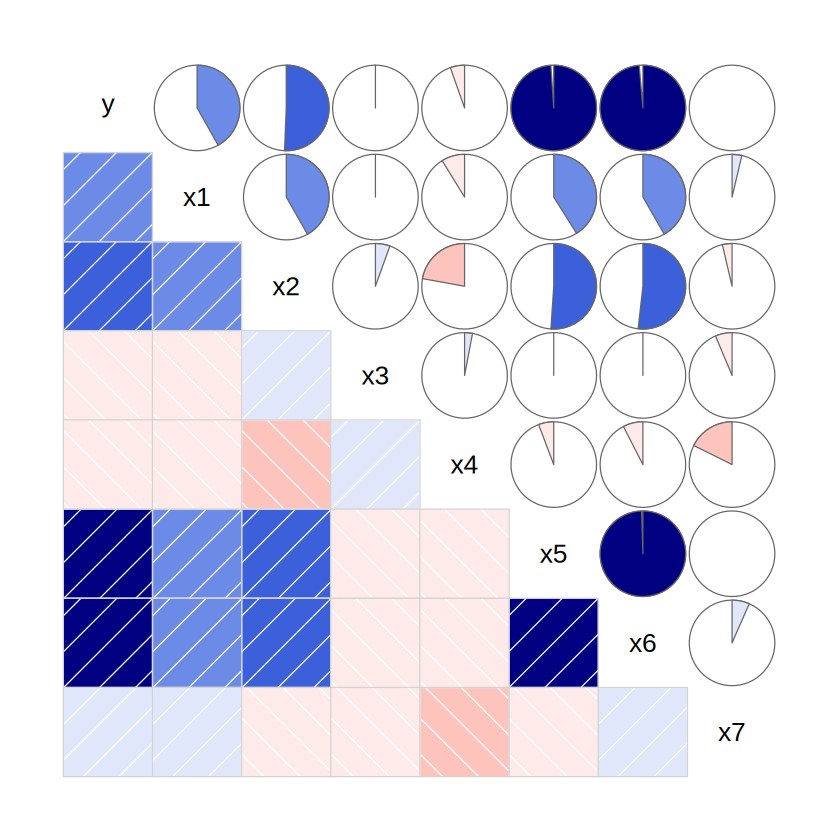

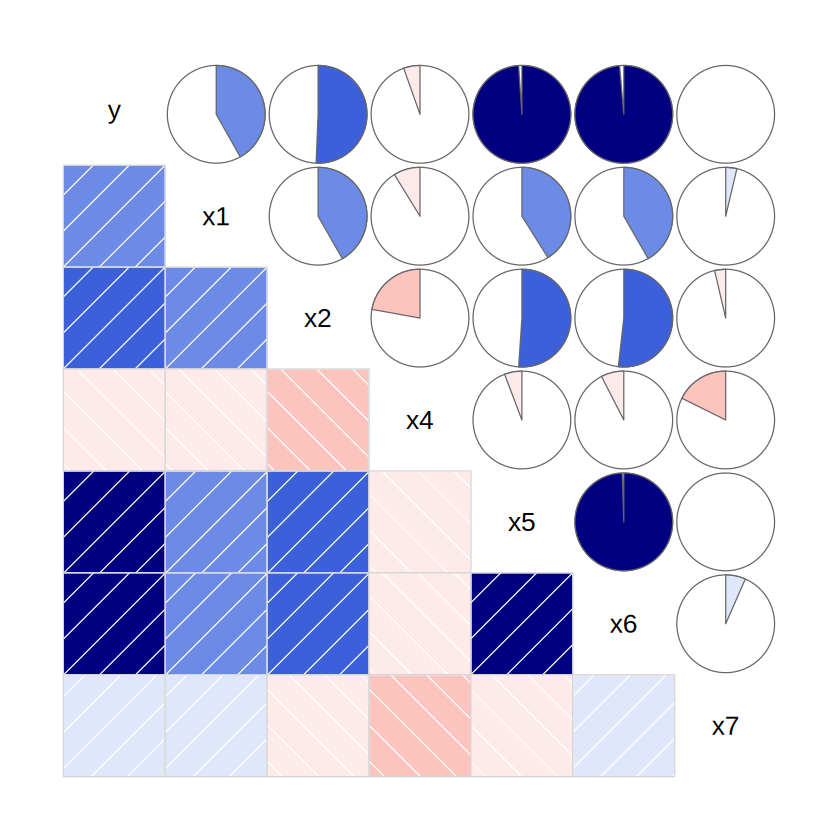

In [ ]:
par(mfrow=c(1,1))
# para diminuir espaços em branco nas margens do gráfico
# The default is c(5, 4, 4, 2) + 0.1
# bottom , left, top, right
par(mar=c(5,5,2,1))

#Exemplo (pacote corrgram)
corrgram(dados[,], order=FALSE, lower.panel=panel.shade, upper.panel=panel.pie, text.panel=panel.txt)

#para excluir alguma variável (coluna)
#exemplo exclui a coluna 4
corrgram(dados[,-c(4)], order=FALSE, lower.panel=panel.shade, upper.panel=panel.pie, text.panel=panel.txt)



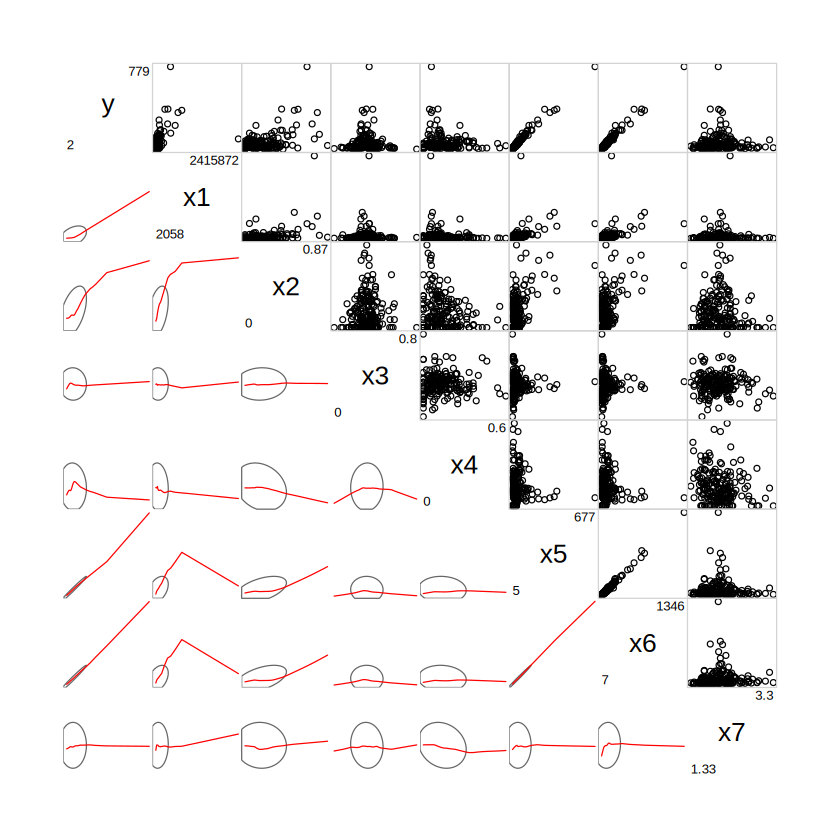

In [ ]:
#Exemplo (pacote corrgram)
corrgram(dados[,], order=FALSE, lower.panel=panel.ellipse, upper.panel=panel.pts, text.panel=panel.txt, diag.panel=panel.minmax)



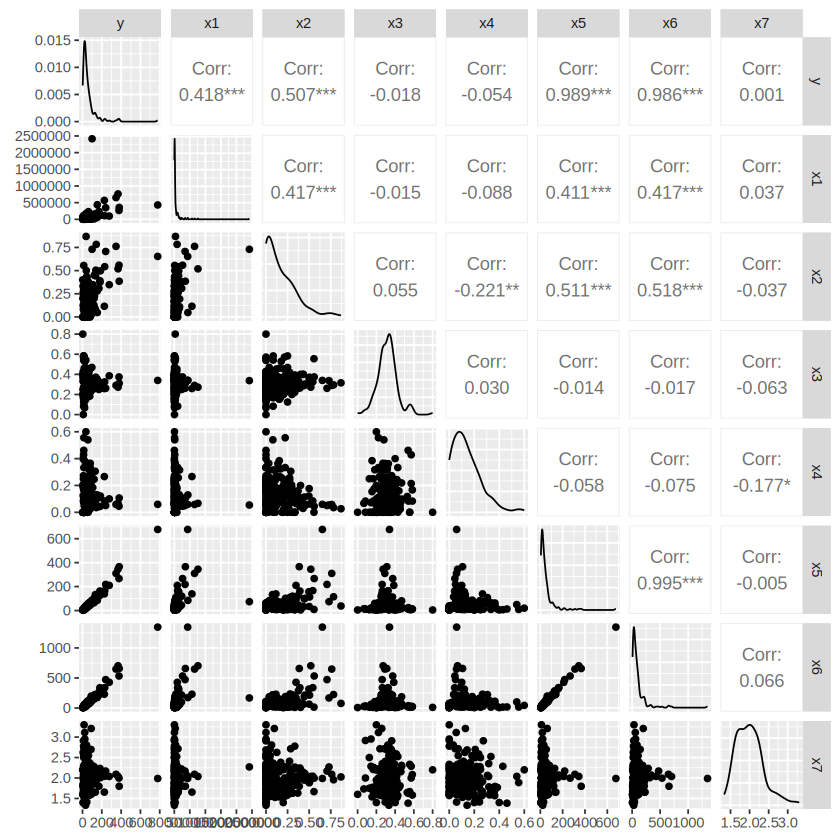

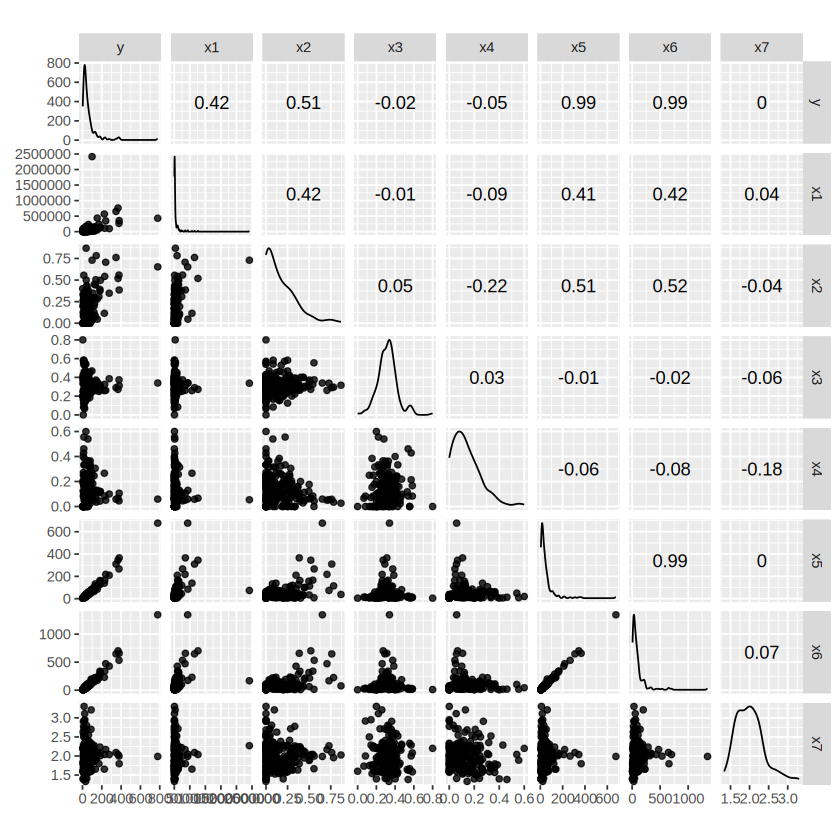

In [ ]:
#Exemplo (pacote GGally)
ggpairs(dados[,])

#Exemplo (pacote GGally)
ggscatmat(dados[,], alpha=0.8)

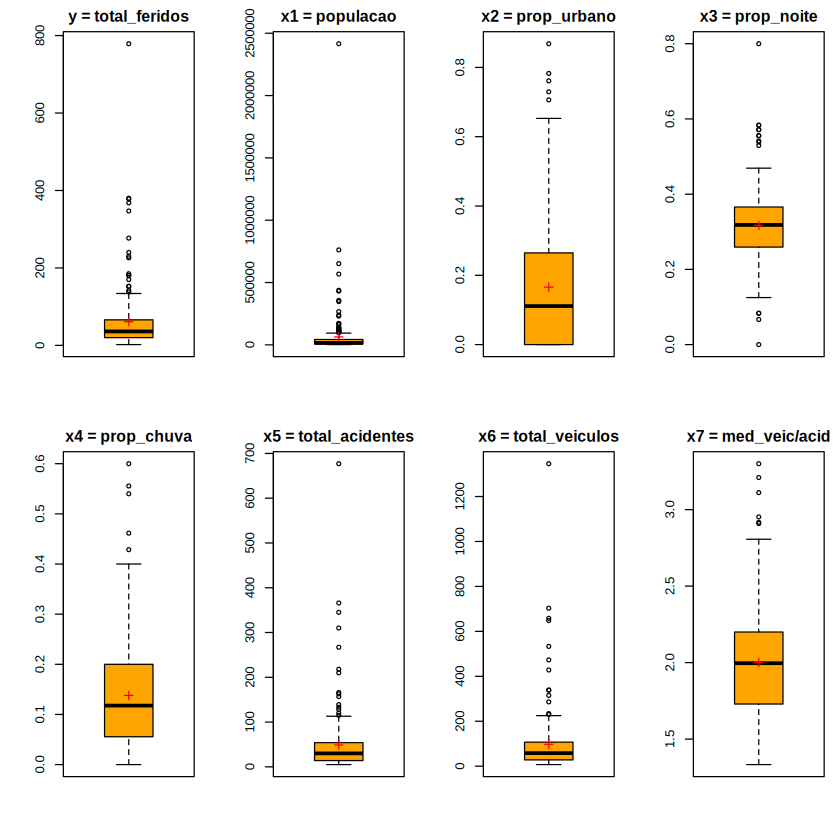

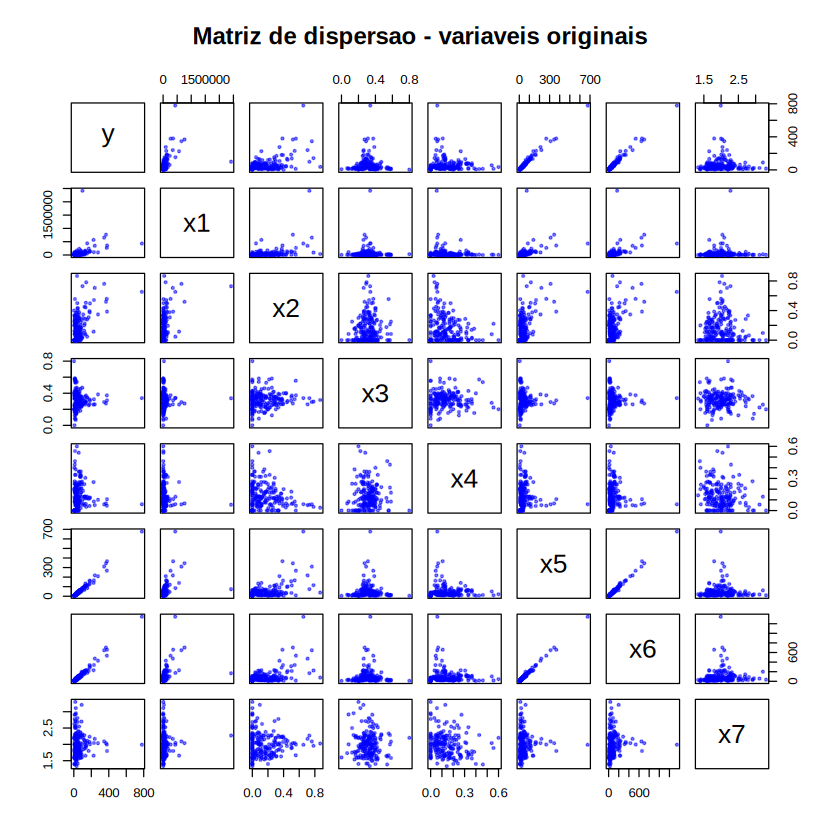

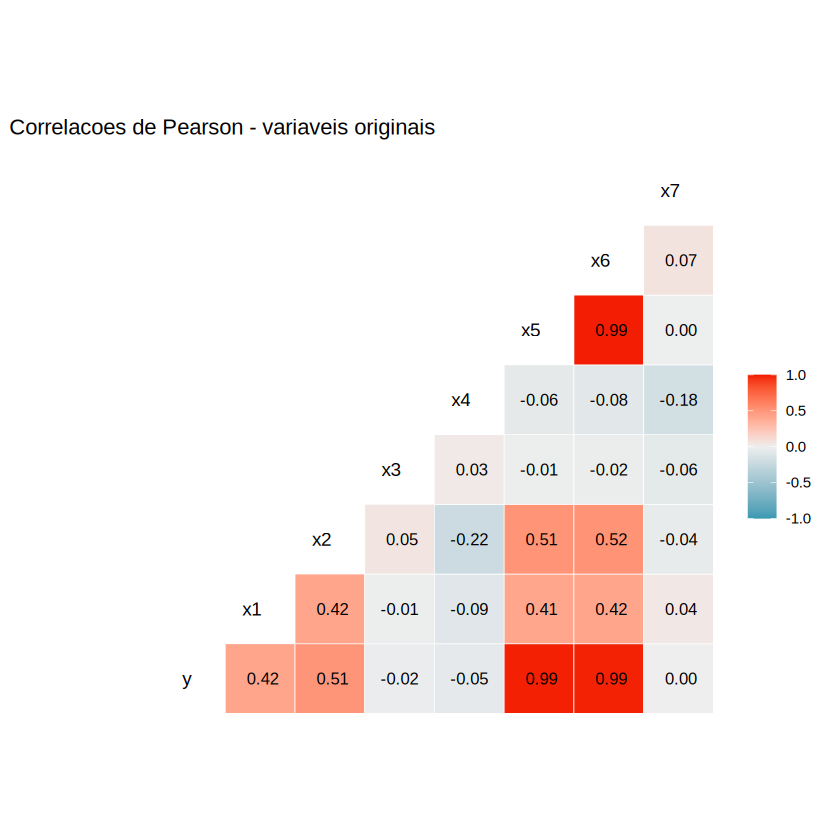

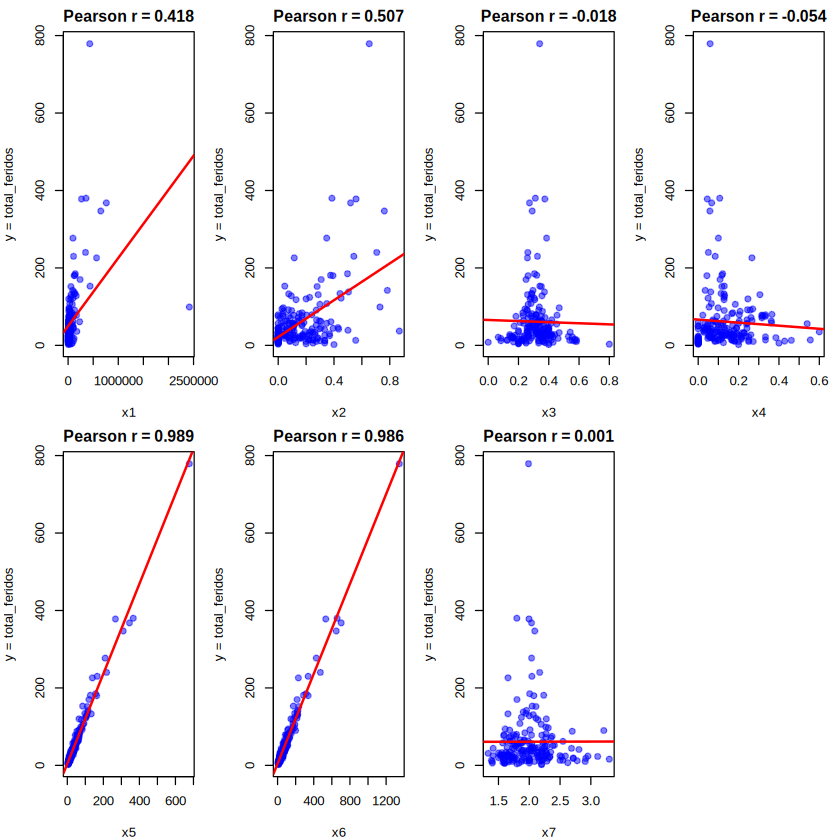

In [ ]:
par(mfrow = c(2, 4), mar = c(4, 4, 2, 1))
boxplot(dados$y,  main = "y = total_feridos", col = "orange"); points(mean(dados$y),  col = "red", pch = 3)
boxplot(dados$x1, main = "x1 = populacao",    col = "orange"); points(mean(dados$x1), col = "red", pch = 3)
boxplot(dados$x2, main = "x2 = prop_urbano",  col = "orange"); points(mean(dados$x2), col = "red", pch = 3)
boxplot(dados$x3, main = "x3 = prop_noite",   col = "orange"); points(mean(dados$x3), col = "red", pch = 3)
boxplot(dados$x4, main = "x4 = prop_chuva",   col = "orange"); points(mean(dados$x4), col = "red", pch = 3)
boxplot(dados$x5, main = "x5 = total_acidentes",   col = "orange"); points(mean(dados$x5), col = "red", pch = 3)
boxplot(dados$x6, main = "x6 = total_veiculos",    col = "orange"); points(mean(dados$x6), col = "red", pch = 3)
boxplot(dados$x7, main = "x7 = med_veic/acid",     col = "orange"); points(mean(dados$x7), col = "red", pch = 3)

# Matriz de dispersao - visao global (originais)
pairs(dados, main = "Matriz de dispersao - variaveis originais",
      pch = 19, cex = 0.5, col = rgb(0, 0, 1, 0.5))

# ggcorr - matriz de correlacao visual (substitui corrgram)
print(ggcorr(dados, label = TRUE, label_round = 2, label_size = 3.5,
             hjust = 0.9, size = 4, layout.exp = 2) +
      ggplot2::ggtitle("Correlacoes de Pearson - variaveis originais"))

# Dispersao individual Y vs cada X
par(mfrow = c(2, 4), mar = c(4, 4, 2, 1))
for (i in 1:7) {
  xi <- dados[[paste0("x", i)]]
  plot(xi, dados$y, xlab = paste0("x", i), ylab = "y = total_feridos",
       pch = 19, col = rgb(0, 0, 1, 0.5),
       main = sprintf("Pearson r = %.3f", cor(dados$y, xi)))
  abline(lm(dados$y ~ xi), col = "red", lwd = 2)
}

**Justificativa:**

* As correlações mais altas são com `total_acidentes` ($x_{5} = 0,989$) e `total_veiculos` ($x_{6} = 0,986$). Muito provalmente essas variáveis são mecanicamente ligadas a Y (mais acidentes gera mais feridos), por isso não serão candidatas ao modelo de regressão final.
* Entre as variáveis realmente interessantes do ponto de vista explicativo, destacam-se prop_urbano ($r = 0,507$) e populacao ($r = 0,418$). As duas apresentam sinais positivos, isto é, maior população e maior proporção de acidentes em área urbana se associam a mais feridos.
`prop_noite`, `prop_chuva` e `media_veiculos_por_acidente` possuem correlações praticamente nulas com Y.

## Transformação Box-Tidwell

### Aplicação Prática da Transformação Box-Tidwell

Nesta etapa, vamos aplicar uma transfomação para identificar potências ótimas de transformação para algumas variáveis explicativas.

Tentamos usar a função `boxTidwell` diretamente do pacote `car`, mas não conseguimos executá-la por conta de valores não numéricos. Foi feito uma nova abordagem, dentro de um laço *loop*, na qual identifica as melhores transformações e não precisa remover uma linha inteira.

No fim, decidimos continuar com o par ($x_1$ e $x_2$) a fim de maximizar a relação linear com $y$ (Total de Feridos).

In [ ]:
eps <- 1e-3
y <- dados$y
x1p <- dados$x1
x2p <- dados$x2 + eps
x3p <- dados$x3 + eps
x4p <- dados$x4 + eps
x5p <- dados$x5
x6p <- dados$x6
x7p <- dados$x7

bt_result <- list()
vars_bt <- list(
  x1 = x1p, x2 = x2p, x3 = x3p, x4 = x4p,
  x5 = x5p, x6 = x6p, x7 = x7p
)

for (nm in names(vars_bt)) {
  res <- tryCatch(
    boxTidwell(y ~ vars_bt[[nm]]),
    error = function(e) {cat("ERRO:", conditionMessage(e), " Não convergiu. \n"); NULL}
  )
  if (!is.null(res)) {
    print(res)
    bt_result[[nm]] <- res
  }
}

ERRO: NA/NaN/Inf in 'x'  Não convergiu. 
 MLE of lambda Score Statistic (t) Pr(>|t|)  
        1.5335              2.1794  0.03053 *
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

iterations =  4 
ERRO: NA/NaN/Inf in 'x'  Não convergiu. 


Warning message in boxTidwell.default(y, X1, X2, max.iter = max.iter, tol = tol, :
“maximum iterations exceeded”


 MLE of lambda Score Statistic (t) Pr(>|t|)  
        -9.716             -2.0782  0.03904 *
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

iterations =  26 
 MLE of lambda Score Statistic (t)  Pr(>|t|)    
       0.93456             -4.2753 3.018e-05 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

iterations =  1 
 MLE of lambda Score Statistic (t) Pr(>|t|)  
       0.95397             -2.5647   0.0111 *
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

iterations =  1 
ERRO: NA/NaN/Inf in 'x'  Não convergiu. 


O Box–Tidwell não convergiu para populacao (há municípios de escala muito diferente — Belo Horizonte ≈ 2,4 milhões contra < 3 mil em Senador José Bento), mas o gráfico de dispersão deixa claro o perfil logarítmico. Para `prop_urbano` o $λ$ estimado é $≈ 1,5$, mas como as correlações de $x_{2}$ e $√x_{2}$ são muito próximas, a transformação é pouco relevante.

Para `prop_chuva` o algoritmo também não convergiu adequadamente (atingiu o número máximo de iterações = 26), produzindo $λ ≈ -9,72$, que não tem interpretação prática (descartado). Para `prop_noite` e `media_veiculos_por_acidente` o Box-Tidwell também não convergiu (NA/NaN/Inf), indicando que essas variáveis não têm forma funcional estável que linearize sua relação com y.


### Análise Gráfica (com Variáveis Transformadas)



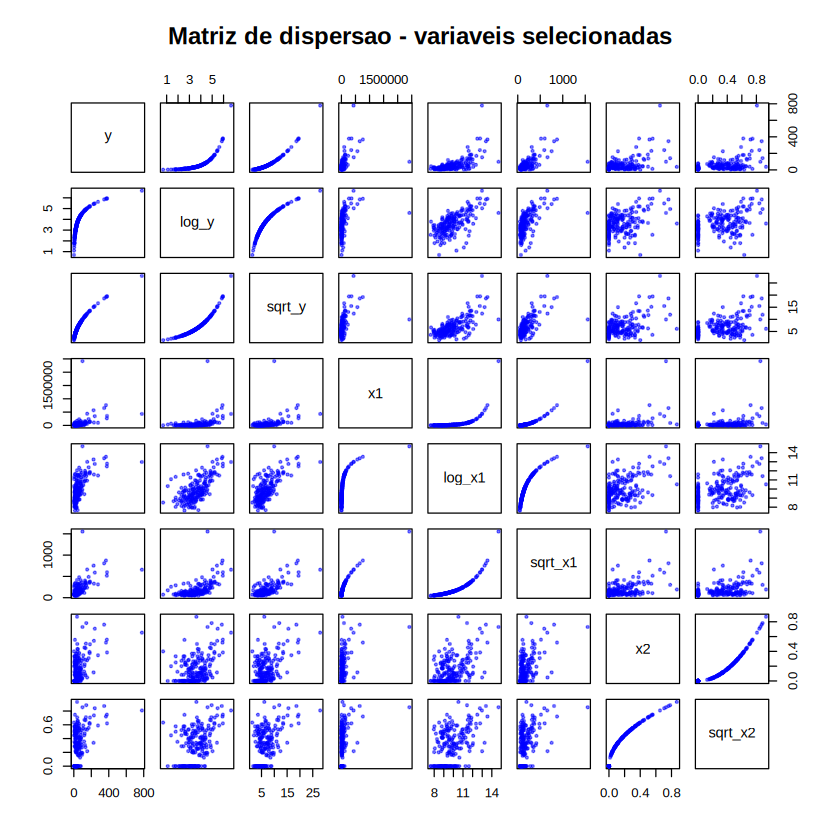

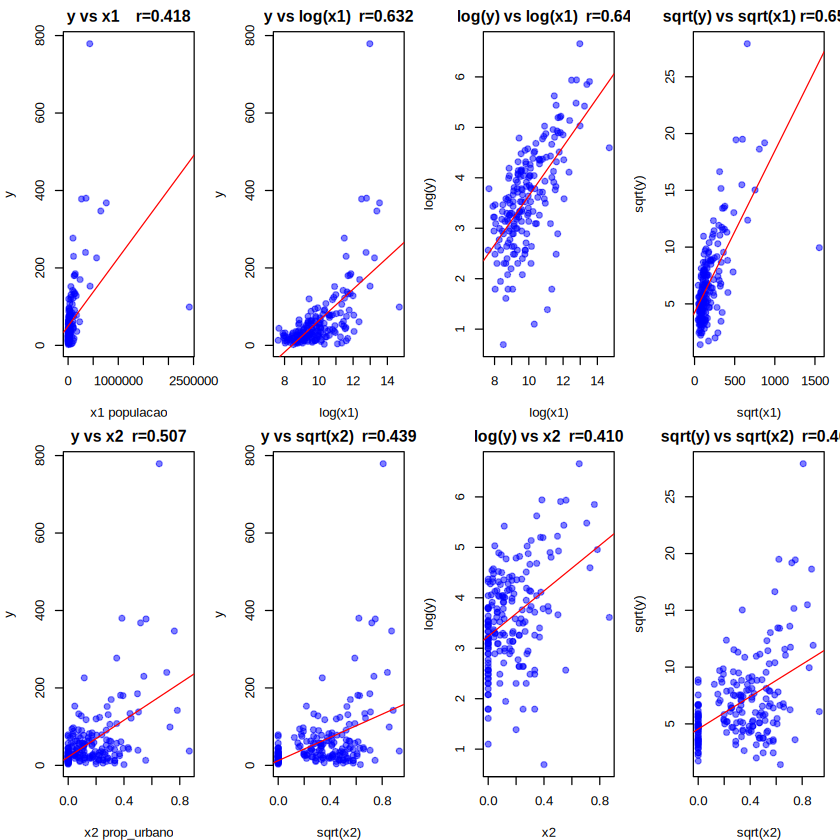

In [ ]:
dd_t <- data.frame(
  y = y,
  log_y = log(y), # apenas para exame alternativo
  sqrt_y = sqrt(y),
  x1 = x1, log_x1 = log(x1), sqrt_x1 = sqrt(x1),
  x2 = x2, sqrt_x2 = sqrt(x2),
  x3 = x3, sqrt_x3 = sqrt(x3),
  x4 = x4, sqrt_x4 = sqrt(x4),
  x5 = x5, log_x5 = log(x5), sqrt_x5 = sqrt(x5),
  x6 = x6, log_x6 = log(x6), sqrt_x6 = sqrt(x6)
)

y <- dados$y
x1 <- dados$x1
x2 <- dados$x2

# Matriz de dispersao limitada apenas às variaveis selecionadas
colunas_selecionadas <- c("y", "log_y", "sqrt_y", "x1", "log_x1", "sqrt_x1", "x2", "sqrt_x2")
pairs(dd_t[, colunas_selecionadas], main = "Matriz de dispersao - variaveis selecionadas",
      pch = 19, cex = 0.5, col = rgb(0, 0, 1, 0.5))

par(mfrow = c(2, 4), mar = c(4, 4, 2, 1))
plot(x1, y, main = sprintf("y vs x1    r=%.3f", cor(y, x1)),
     xlab="x1 populacao", ylab="y", pch=19, col=rgb(0,0,1,0.5));            abline(lm(y~x1), col="red")
plot(log(x1), y, main = sprintf("y vs log(x1)  r=%.3f", cor(y, log(x1))),
     xlab="log(x1)", ylab="y", pch=19, col=rgb(0,0,1,0.5));                 abline(lm(y~log(x1)), col="red")
plot(log(x1), log(y), main = sprintf("log(y) vs log(x1)  r=%.3f", cor(log(y), log(x1))),
     xlab="log(x1)", ylab="log(y)", pch=19, col=rgb(0,0,1,0.5));            abline(lm(log(y)~log(x1)), col="red")
plot(sqrt(x1), sqrt(y),  main = sprintf("sqrt(y) vs sqrt(x1) r=%.3f", cor(sqrt(y), sqrt(x1))),
     xlab="sqrt(x1)", ylab="sqrt(y)", pch=19, col=rgb(0,0,1,0.5));          abline(lm(sqrt(y)~sqrt(x1)), col="red")

plot(x2, y, main = sprintf("y vs x2  r=%.3f", cor(y, x2)),
     xlab="x2 prop_urbano", ylab="y", pch=19, col=rgb(0,0,1,0.5));          abline(lm(y~x2), col="red")
plot(sqrt(x2), y, main = sprintf("y vs sqrt(x2)  r=%.3f", cor(y, sqrt(x2))),
     xlab="sqrt(x2)", ylab="y", pch=19, col=rgb(0,0,1,0.5));                abline(lm(y~sqrt(x2)), col="red")
plot(x2, log(y), main = sprintf("log(y) vs x2  r=%.3f", cor(log(y), x2)),
     xlab="x2", ylab="log(y)", pch=19, col=rgb(0,0,1,0.5));                 abline(lm(log(y)~x2), col="red")
plot(sqrt(x2), sqrt(y),  main = sprintf("sqrt(y) vs sqrt(x2)  r=%.3f", cor(sqrt(y), sqrt(x2))),
     xlab="sqrt(x2)", ylab="sqrt(y)", pch=19, col=rgb(0,0,1,0.5));          abline(lm(sqrt(y)~sqrt(x2)), col="red")

## Parte 2

Um modelo de regressão linear simples relaciona a variável resposta $Y$ com apenas uma variável explicativa $x$

\
$$Y_{i}|x_{i}=\beta_{0}+\beta_{1}x_{i}+E_{i},$$

\
sendo $E_{i}$~$N(0,\sigma^{2})$ e $cov(E_{i},E_{j})=0$ para $i\ne j$.

\
Assim sendo, tem-se

$$\mu_{i}=E(Y_{i}|x_{i})=\beta_{0}+\beta_{1}x_{i}$$

## Coeficiente de Pearson

In [ ]:
y <- log(dados$y) # variavel resposta transformada
x <- log(dados$x1) # populacao em log
pearson <- cor(y, x)
pearson

y <- dados$y # variavel resposta não-transformada
x <- log(dd_t$log_x1) # populacao em log
pearson <- cor(y, x)
pearson

[1] 0.6469659

[1] 0.6090924

## Coeficiente de Spearman


In [ ]:
y <- log(dados$y) # variavel resposta transformada
x <- log(dados$x1) # populacao em log
spearman <- cor(y, x, method = "spearman")
spearman

y <- dados$y
x <- log(dados$x1) # populacao em log
spearman <- cor(y, x, method = "spearman")
spearman

[1] 0.628069

[1] 0.628069

## Estimação dos parâmetros do modelo $\beta_0$ e $\beta_1$

In [ ]:
y <- log(dados$y) # variavel resposta transformada
x <- log(dados$x1) # populacao em log

modelo <- lm(y ~ x)
summary(modelo) # estimativas e testes dos coeficientes


Call:
lm(formula = y ~ x)

Residuals:
    Min      1Q  Median      3Q     Max 
-2.7841 -0.3507  0.1305  0.5423  1.5687 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept) -1.21902    0.41533  -2.935  0.00374 ** 
x            0.48620    0.04146  11.726  < 2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.7489 on 191 degrees of freedom
Multiple R-squared:  0.4186,	Adjusted R-squared:  0.4155 
F-statistic: 137.5 on 1 and 191 DF,  p-value: < 2.2e-16


Hipóteses de `(Intercept)` -> $H_{0} : \beta_{0} = 0$,
$H_{a} : \beta_{0} \ne 0$

Hipóteses de `x` -> $H_{0} : \beta_{1} = 0$,
$H_{a} : \beta_{1} \ne 0$

**Interpretação dos coeficientes.**

  * $β̂₁ = 0,4862$: quando a população dobra (log aumenta em ln 2 ≈ 0,693), o número esperado de feridos é multiplicado aproximadamente por 20, ou seja, aumento esperado de 40%.
  $β₁$ é significativamente diferente de zero ($t = 11,7; pvalor < 10⁻¹⁵$). Como o pvalor é menor que $\alpha = 0,05$, rejeita-se $H_{0}$.

  * $R² = 0,42$: a população em log explica ~42% da variabilidade de `log(total_feridos)`. Sobra bastante variabilidade para ser explicada por outras variáveis.


## Estimação de $\beta_0$ e $\beta_1$ na forma matricial

In [ ]:
modelo <- lm(y~x)
X <- model.matrix(modelo)
X

# ou de forma manual
#n=10
#int<-matrix(1,n,1) # vetor de 1s
#X<-cbind(int,x);X  # matriz

Beta <- solve(t(X)%*%X)%*%t(X)%*%y # vetor com estimativas dos coeficientes
Beta

,(Intercept),x
1,1,12.974868
2,1,12.784877
3,1,12.493358
4,1,13.543485
5,1,13.387367
6,1,11.485842
7,1,12.756996
8,1,11.594017
9,1,13.249401
10,1,11.869557


(Intercept),-1.2190195
x,0.4862002


## Estimação da variância dos erros $\sigma^2$

Se as suposições do modelo são satisfeitas então o erro quadrático médio dos resíduos estima a variância dos erros
e portanto, a raiz quadrada do erro quadrático médio dos resíduos estima o erro padrão dos erros.

In [ ]:
modelo <- lm(y~x)
anova(modelo)
QMRes <- anova(modelo)[["Mean Sq"]][2]
QMRes

,Df,Sum Sq,Mean Sq,F value,Pr(>F)
,<int>,<dbl>,<dbl>,<dbl>,<dbl>
x,1,77.11501,77.1150113,137.4975,2.862683e-24
Residuals,191,107.12170,0.5608466,NA,NA


[1] 0.5608466

$QM_{\operatorname{\mathrm{Re}}siduo}=0,5609$. Para o desvio padrão, fazemos a raiz quadrada de $0,5609$.

### Estimação do erro padrão dos erros $\sigma$


In [ ]:
modelo <- lm(y~x)
raiz_QMRes <- sqrt(anova(modelo)[["Mean Sq"]][2])
raiz_QMRes

[1] 0.7488969

## Tipos de resíduos

Os resíduos são utilizados na verificação das suposições do modelo de regressão e na identificação de observações atípicas. Existem diferentes tipos de resíduos, sendo alguns mais apropriados para a avaliação das suposições e outros para a identificação de observações atípicas.

Esses resíduos se distinguem pela forma como são calculados, especialmente pela maneira como consideram a variabilidade dos erros e a alavancagem das observações.

### Resíduos ordinários

Os resíduos ordinários são definidos como as diferenças entre os valores observados e os valores ajustados pelo modelo de regressão.

Sua expressão é:

$$
e_i = y_i - \hat{y}_i
$$

em que:

- $y_i$ é o valor observado da variável resposta;
- $\hat{y}_i$ é o valor ajustado pelo modelo.

No R, são calculados pela função `resid(modelo)`.

In [ ]:
modelo <- lm(y~x)
residuos<-resid(modelo)
residuos

1            2            3            4            5            6 
 1.568646871  0.943180299  1.079639868  0.542256668  0.559403140  1.258617888 
           7            8            9           10           11           12 
 0.497203692  1.020085050  0.197692461  0.668393683  0.675547932  0.721874353 
          13           14           15           16           17           18 
 0.333792946 -0.065828016  0.933582851  0.623701395  0.481618209  0.359353553 
          19           20           21           22           23           24 
 0.409426545  0.750403866  0.238507948  0.752792147  0.430315359  1.420922482 
          25           26           27           28           29           30 
 0.741684263  0.838940821  0.370853365 -1.331823103  0.961738618  1.007816805 
          31           32           33           34           35           36 
 0.711616378  0.005872373  0.710764293  1.053410483  0.171240638  0.266291669 
          37           38           39           40           41           42 
 0.624812341  0.429429664  0.336521892 -0.277479369  0.426384589  0.373117569 
          43           44           45           46           47           48 
 0.763663839 -0.110424461  0.979326384  0.716912018  0.330527630  0.583006319 
          49           50           51           52           53           54 
 0.496855121  1.106177952  0.722037133  0.799263319  0.603380024  0.728227899 
          55           56           57           58           59           60 
 0.694863274 -0.216687516 -0.673461202  0.743150355  0.717634515  0.953129137 
          61           62           63           64           65           66 
 0.380628493  0.544310457  0.360215321  0.250098685  0.618198623 -0.288179797 
          67           68           69           70           71           72 
 0.363280160  0.918946873  0.670932110 -0.168027287 -0.438303794  0.337969385 
          73           74           75           76           77           78 
 0.591618225  0.195657468  0.250837816 -0.581798401  0.578990947  0.111993630 
          79           80           81           82           83           84 
 0.081606902 -0.027435892  0.349405504  1.272712412  0.472519743 -0.631002049 
          85           86           87           88           89           90 
 0.306766175  0.526132420 -0.318412653 -0.240150797  0.388942957  0.199497112 
          91           92           93           94           95           96 
 0.467493532  0.012968006 -0.284467341  0.540952466 -1.059684191  0.590490239 
          97           98           99          100          101          102 
-0.498841425  0.514880737  0.327918408  0.086622518  0.121939936 -0.169279883 
         103          104          105          106          107          108 
-0.012574647  0.393945551 -0.614801738  0.558703850  0.778631078  0.808841552 
         109          110          111          112          113          114 
 0.237255411 -0.228029340 -0.073982058 -0.111773108 -0.057241370 -0.428764781 
         115          116          117          118          119          120 
-0.048802461  0.438284955  0.130553729  0.276556053  0.175686341 -0.333753030 
         121          122          123          124          125          126 
-0.049894314 -0.684765144  0.156340162 -0.348899085  0.171143895 -0.073297157 
         127          128          129          130          131          132 
 0.552381249  0.578047776 -0.139835483  0.142797212 -0.114618493  0.303149822 
         133          134          135          136          137          138 
 0.090173191  0.170661443 -0.299425384 -0.504999802 -0.770880064 -0.135174799 
         139          140          141          142          143          144 
-1.166186819 -0.737526631  0.388880904 -0.175833757 -0.313882539  0.183887544 
         145          146          147          148          149          150 
-0.105620784 -0.283647649  0.289933509 -0.497506904  0.058727722 -0.140361564 
         151          152          153          154          

### Resíduos padronizados

Os resíduos padronizados são obtidos dividindo cada resíduo ordinário pela estimativa do desvio-padrão dos erros.

Sua expressão é:

$$
z_i = \frac{e_i}{\hat{\sigma}}
    = \frac{y_i-\hat{y}_i}{\sqrt{QM_{\text{Erro}}}}
$$

em que:

- $e_i=y_i-\hat{y}_i$ é o resíduo ordinário;
- $\hat{\sigma}^2=QM_{\text{Erro}}$ é a estimativa da variância dos erros;
- $\hat{\sigma}=\sqrt{QM_{\text{Erro}}}$ é a estimativa do desvio-padrão dos erros.

No R, os resíduos padronizados podem ser calculados por:

`resid(modelo) / sigma(modelo)`

In [ ]:
resid(modelo) / sigma(modelo)

estimativa_ep_erro=sqrt(anova(modelo)[["Mean Sq"]][2]);  estimativa_ep_erro   # estimativa do erro padrão dos erros

res_padronizado=residuos/estimativa_ep_erro; res_padronizado # resíduos padronizados

1            2            3            4            5            6 
 2.094609903  1.259426090  1.441640180  0.724073855  0.746969492  1.680629044 
           7            8            9           10           11           12 
 0.663914738  1.362116794  0.263978206  0.892504267  0.902057317  0.963916861 
          13           14           15           16           17           18 
 0.445712813 -0.087899971  1.246610642  0.832826778  0.643103485  0.479843822 
          19           20           21           22           23           24 
 0.546706152  1.002012242  0.318479014  1.005201308  0.574598928  1.897353927 
          25           26           27           28           29           30 
 0.990368980  1.120235398  0.495199491 -1.778379769  1.284206962  1.345735040 
          31           32           33           34           35           36 
 0.950219416  0.007841363  0.949081628  1.406616154  0.228657159  0.355578542 
          37           38           39           40           41           42 
 0.834310220  0.573416263  0.449356767 -0.370517447  0.569350182  0.498222875 
          43           44           45           46           47           48 
 1.019718249 -0.147449482  1.307691858  0.957290669  0.441352646  0.778486753 
          49           50           51           52           53           54 
 0.663449292  1.477076411  0.964134220  1.067254136  0.805691705  0.972400733 
          55           56           57           58           59           60 
 0.927849041 -0.289342251 -0.899270912  0.992326648  0.958255416  1.272710746 
          61           62           63           64           65           66 
 0.508252192  0.726816274  0.480994539  0.333956095  0.825478940 -0.384805699 
          67           68           69           70           71           72 
 0.485087010  1.227067261  0.895893823 -0.224366380 -0.585265865  0.451289601 
          73           74           75           76           77           78 
 0.789986208  0.261260885  0.334943053 -0.776873824  0.773125037  0.149544790 
          79           80           81           82           83           84 
 0.108969475 -0.036635072  0.466560219  1.699449423  0.630954328 -0.842575320 
          85           86           87           88           89           90 
 0.409624040  0.702543190 -0.425175550 -0.320672706  0.519354473  0.266387952 
          91           92           93           94           95           96 
 0.624242842  0.017316143 -0.379848467  0.722332357 -1.414993420  0.788480010 
          97           98           99          100          101          102 
-0.666101598  0.687518849  0.437868559  0.115666813  0.162826065 -0.226038968 
         103          104          105          106          107          108 
-0.016790892  0.526034424 -0.820943090  0.746035731  1.039703962  1.080043925 
         109          110          111          112          113          114 
 0.316806505 -0.304486958 -0.098788040 -0.149250327 -0.076434246 -0.572528447 
         115          116          117          118          119          120 
-0.065165793  0.585240708  0.174328040  0.369284546  0.234593494 -0.445659514 
         121          122          123          124          125          126 
-0.066623742 -0.914365035  0.208760594 -0.465884000  0.228527977 -0.097873494 
         127          128          129          130          131          132 
 0.737593179  0.771865623 -0.186721941  0.190676730 -0.153049763  0.404795133 
         133          134          135          136          137          138 
 0.120408017  0.227883761 -0.399821901 -0.674324863 -1.029354054 -0.180498541 
         139          140          141          142          143          144 
-1.557206089 -0.984817305  0.519271613 -0.234790338 -0.419126501  0.245544537 
         145          146          147          148          149          150 
-0.141035146 -0.378753934  0.387147427 -0.664319616  0.078418967 -0.187424415 
         151          152          153          154          

[1] 0.7488969

1            2            3            4            5            6 
 2.094609903  1.259426090  1.441640180  0.724073855  0.746969492  1.680629044 
           7            8            9           10           11           12 
 0.663914738  1.362116794  0.263978206  0.892504267  0.902057317  0.963916861 
          13           14           15           16           17           18 
 0.445712813 -0.087899971  1.246610642  0.832826778  0.643103485  0.479843822 
          19           20           21           22           23           24 
 0.546706152  1.002012242  0.318479014  1.005201308  0.574598928  1.897353927 
          25           26           27           28           29           30 
 0.990368980  1.120235398  0.495199491 -1.778379769  1.284206962  1.345735040 
          31           32           33           34           35           36 
 0.950219416  0.007841363  0.949081628  1.406616154  0.228657159  0.355578542 
          37           38           39           40           41           42 
 0.834310220  0.573416263  0.449356767 -0.370517447  0.569350182  0.498222875 
          43           44           45           46           47           48 
 1.019718249 -0.147449482  1.307691858  0.957290669  0.441352646  0.778486753 
          49           50           51           52           53           54 
 0.663449292  1.477076411  0.964134220  1.067254136  0.805691705  0.972400733 
          55           56           57           58           59           60 
 0.927849041 -0.289342251 -0.899270912  0.992326648  0.958255416  1.272710746 
          61           62           63           64           65           66 
 0.508252192  0.726816274  0.480994539  0.333956095  0.825478940 -0.384805699 
          67           68           69           70           71           72 
 0.485087010  1.227067261  0.895893823 -0.224366380 -0.585265865  0.451289601 
          73           74           75           76           77           78 
 0.789986208  0.261260885  0.334943053 -0.776873824  0.773125037  0.149544790 
          79           80           81           82           83           84 
 0.108969475 -0.036635072  0.466560219  1.699449423  0.630954328 -0.842575320 
          85           86           87           88           89           90 
 0.409624040  0.702543190 -0.425175550 -0.320672706  0.519354473  0.266387952 
          91           92           93           94           95           96 
 0.624242842  0.017316143 -0.379848467  0.722332357 -1.414993420  0.788480010 
          97           98           99          100          101          102 
-0.666101598  0.687518849  0.437868559  0.115666813  0.162826065 -0.226038968 
         103          104          105          106          107          108 
-0.016790892  0.526034424 -0.820943090  0.746035731  1.039703962  1.080043925 
         109          110          111          112          113          114 
 0.316806505 -0.304486958 -0.098788040 -0.149250327 -0.076434246 -0.572528447 
         115          116          117          118          119          120 
-0.065165793  0.585240708  0.174328040  0.369284546  0.234593494 -0.445659514 
         121          122          123          124          125          126 
-0.066623742 -0.914365035  0.208760594 -0.465884000  0.228527977 -0.097873494 
         127          128          129          130          131          132 
 0.737593179  0.771865623 -0.186721941  0.190676730 -0.153049763  0.404795133 
         133          134          135          136          137          138 
 0.120408017  0.227883761 -0.399821901 -0.674324863 -1.029354054 -0.180498541 
         139          140          141          142          143          144 
-1.557206089 -0.984817305  0.519271613 -0.234790338 -0.419126501  0.245544537 
         145          146          147          148          149          150 
-0.141035146 -0.378753934  0.387147427 -0.664319616  0.078418967 -0.187424415 
         151          152          153          154          

### Resíduo studentizado internamente

O resíduo studentizado internamente é calculado pela função `rstandard(modelo)` no R.

Sua expressão é:

$$
r_i = \frac{e_i}{\hat{\sigma}\sqrt{1-h_{ii}}}
$$

em que:

- $e_i = y_i - \hat{y}_i$ é o resíduo ordinário;
- $\hat{\sigma} = \sqrt{QM_{\text{Resíduo}}}$ é a estimativa do desvio-padrão dos erros;
- $h_{ii}$ é o elemento da diagonal principal da matriz de projeção:

$$
H = X(X'X)^{-1}X'
$$

O resíduo studentizado internamente também é denominado **resíduo padronizado internamente**.

In [ ]:
res_pad<-rstandard(modelo); res_pad

### Resíduos studentizados externamente (utilizado na análise de influencia)

Os resíduos studentizados externamente são obtidos dividindo cada resíduo ordinário por uma estimativa de seu desvio-padrão, calculada sem considerar a observação correspondente. Esses resíduos são especialmente úteis na identificação de observações atípicas.

Sua expressão é:

$$
t_i = \frac{e_i}{\hat{\sigma}_{(i)}\sqrt{1-h_{ii}}}
$$

em que:

- $e_i=y_i-\hat{y}_i$ é o resíduo ordinário;
- $\hat{\sigma}_{(i)}$ é a estimativa do desvio-padrão dos erros, obtida sem a observação $i$;
- $h_{ii}$ é o elemento da diagonal principal da matriz de projeção $H=X(X'X)^{-1}X'$.

No R, são calculados pela função `rstudent(modelo)`.

In [ ]:
r_studentizado <- rstudent(modelo)
r_studentizado

1            2            3            4            5            6 
 2.150800219  1.280982614  1.464594317  0.740121852  0.762242828  1.699644726 
           7            8            9           10           11           12 
 0.673013801  1.374699297  0.268614750  0.899596622  0.908943354  0.970983335 
          13           14           15           16           17           18 
 0.450126538 -0.089193012  1.253607996  0.837189283  0.646743908  0.482845956 
          19           20           21           22           23           24 
 0.549851339  1.006392090  0.320668381  1.009242551  0.577285875  1.916289168 
          25           26           27           28           29           30 
 0.994052224  1.124323838  0.497019594 -1.860748449  1.289781523  1.352206881 
          31           32           33           34           35           36 
 0.952709351  0.007882414  0.951513184  1.414281187  0.229314158  0.356341797 
          37           38           39           40           41           42 
 0.835938416  0.574306031  0.450109169 -0.373203618  0.570203141  0.498958950 
          43           44           45           46           47           48 
 1.022513168 -0.148101202  1.314219193  0.959597192  0.441892971  0.779734750 
          49           50           51           52           53           54 
 0.664230751  1.488312148  0.966664630  1.070935539  0.807075501  0.975045736 
          55           56           57           58           59           60 
 0.930125093 -0.290419781 -0.909413066  0.995376205  0.961002378  1.280413848 
          61           62           63           64           65           66 
 0.508593300  0.727867716  0.481291194  0.334118014  0.827163103 -0.386130774 
          67           68           69           70           71           72 
 0.485378103  1.234290639  0.898406737 -0.224741905 -0.587886016  0.451523137 
          73           74           75           76           77           78 
 0.791699316  0.261304078  0.335035099 -0.781369896  0.775063735  0.149556509 
          79           80           81           82           83           84 
 0.108976003 -0.036643918  0.466908460  1.726309046  0.631966469 -0.847530393 
          85           86           87           88           89           90 
 0.409858518  0.704169035 -0.425861470 -0.320998239  0.519985686  0.266467424 
          91           92           93           94           95           96 
 0.625567151  0.017315709 -0.380184490  0.724688775 -1.432579237  0.791724407 
          97           98           99          100          101          102 
-0.667836848  0.689820129  0.438562492  0.115689581  0.162877842 -0.226074022 
         103          104          105          106          107          108 
-0.016790999  0.527290311 -0.823735851  0.749535155  1.048515416  1.090301609 
         109          110          111          112          113          114 
 0.317235000 -0.304553702 -0.098806208 -0.149281815 -0.076457571 -0.573092635 
         115          116          117          118          119          120 
-0.065187018  0.587723705  0.174562374  0.370250558  0.234988903 -0.445881577 
         121          122          123          124          125          126 
-0.066662332 -0.917023919  0.209131245 -0.466137632  0.228961817 -0.097937777 
         127          128          129          130          131          132 
 0.742966533  0.777848700 -0.186810867  0.191101664 -0.153155556  0.406393603 
         133          134          135          136          137          138 
 0.120660324  0.228529592 -0.400059245 -0.675118881 -1.032637782 -0.180682616 
         139          140          141          142          143          144 
-1.571548776 -0.987622698  0.522443946 -0.235050714 -0.419555906  0.246603054 
         145          146          147          148          149          150 
-0.141277092 -0.379157009  0.389616563 -0.665196976  0.078687573 -0.187774514 
         151          152          153          154          

# Verificação das suposições do modelo de regressão

## Para verificar as Suposições do Modelo

Para verificar se as suposições assumidas $E_{i}$~$N(0,\sigma^{2})$ e $cov(E_{i},E_{j})=0$ para $i\ne j$ são satisfeitas utilizamos os resíduos (valor observado - valor ajustado) já que os erros aleatórios no modelo são desconhecidos.

Os resíduos mais apropriados para a verificação das suposições do modelo são os resíduos studentizados internamente.

## Análise gráfica dos resíduos

[1] 191 192

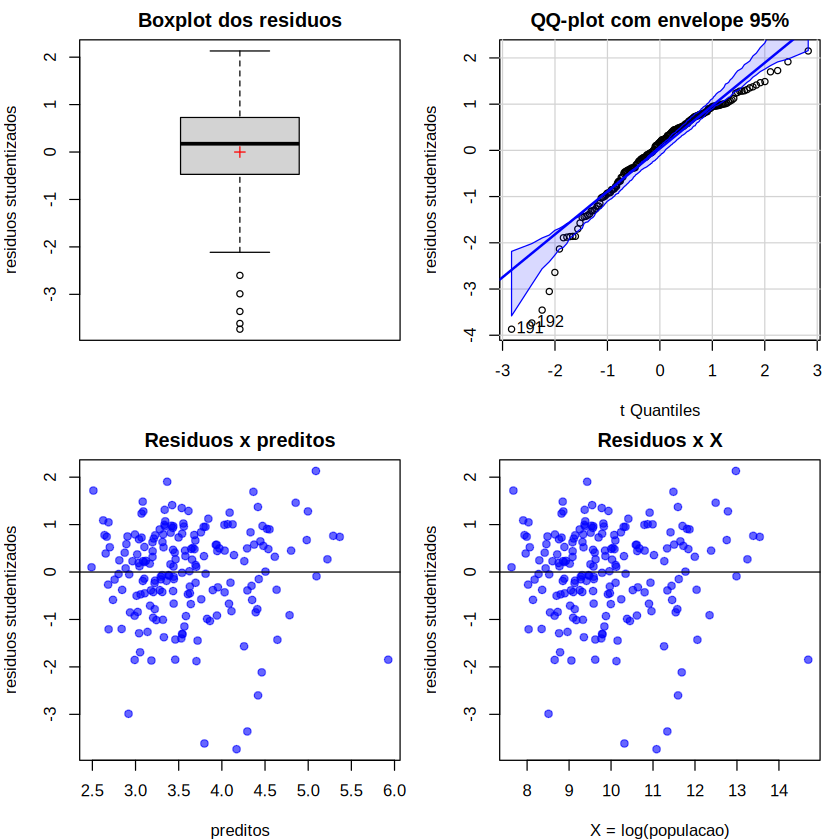

In [ ]:
# não sei pq mas funcionou
dados_modelo <- data.frame(
  y_trans = as.numeric(log(dados$y)),
  x_trans = as.numeric(log(dados$x1))
)
modelo <- lm(y_trans ~ x_trans, data = dados_modelo)

# --- Residuos
residuos        <- resid(modelo)
res_padronizado <- residuos / sigma(modelo)
res_pad_int     <- rstandard(modelo)   # studentizado interno
res_studen_ext  <- rstudent(modelo)    # studentizado externo

# --- Analise grafica de residuos
preditos <- predict(modelo)
par(mfrow = c(2, 2), mar = c(4, 4, 2, 1))
boxplot(res_pad_int, ylab = "residuos studentizados", main = "Boxplot dos residuos")
points(mean(res_pad_int), col = "red", pch = 3)

# Agora o qqPlot funcionará perfeitamente, pois o modelo conhece a origem limpa dos dados
car::qqPlot(modelo, envelope = 0.95, ylab = "residuos studentizados",
            main = "QQ-plot com envelope 95%")

plot(preditos, res_pad_int, xlab = "preditos", ylab = "residuos studentizados",
     main = "Residuos x preditos", pch = 19, col = rgb(0,0,1,0.6)); abline(h = 0)

plot(dados_modelo$x_trans, res_pad_int, xlab = "X = log(populacao)", ylab = "residuos studentizados",
     main = "Residuos x X", pch = 19, col = rgb(0,0,1,0.6));          abline(h = 0)

Nos gráficos de dispersão, os valores estão entre $0$, com o gráfico de resíduos x preditos não aparentarem um padrão evidente de funil (aumento ou diminuição progressiva da dispersão). Apenas pelo gráfico, "poderiamos assumir" uma variância constante.

**Box-plot:** a caixa ficou bem assimétrica com vários outliers na parte inferior, indicando uma possível assimetria negativa. Podemos assumir também que os resíduos não seguem perfeitamente uma distribuição normal, principalmente na cauda inferior.

**QQ-plot:** a maior parte dos pontos acompanha aproximadamente a reta de referência. Entretanto, alguns pontos na cauda inferior se afastam da reta e ultrapassam o envelope de 95%.

## Testes de normalidade



In [ ]:
# testes de normalidade
t_norm_shapiro <- shapiro.test(rstandard(modelo))
t_norm_ad <- nortest::ad.test(rstandard(modelo))
t_norm_lillie <- nortest::lillie.test(rstandard(modelo))
t_norm_cvm <- nortest::cvm.test(rstandard(modelo))
t_norm_sf <- nortest::sf.test(rstandard(modelo))
alpha_norm <- 0.05

testes_norm <- c(
  "Shapiro–Wilk", "Anderson–Darling", "Lilliefors",
  "Cramér–von Mises", "Shapiro–Francia"
)
estatisticas_norm <- as.numeric(c(
  t_norm_shapiro$statistic, t_norm_ad$statistic,
  t_norm_lillie$statistic, t_norm_cvm$statistic,
  t_norm_sf$statistic
))
pvalores_norm <- c(
  t_norm_shapiro$p.value, t_norm_ad$p.value,
  t_norm_lillie$p.value, t_norm_cvm$p.value,
  t_norm_sf$p.value
)
resultados_norm <- data.frame(
  Teste = testes_norm,
  Estatistica = estatisticas_norm,
  p_valor = pvalores_norm,
  Decisao = ifelse(pvalores_norm <= alpha_norm,
                   "Rejeitar H0", "Não rejeitar H0")
)

# Manter os valores numéricos originais e formatar apenas a exibição.
tabela_norm <- resultados_norm
tabela_norm$Estatistica <- formatC(estatisticas_norm,
                                  format = "f", digits = 4, decimal.mark = ",")
tabela_norm$p_valor <- ifelse(
  pvalores_norm < 1e-12,
  "< 0,000000000001",
  formatC(pvalores_norm, format = "f", digits = 12, decimal.mark = ",")
)
knitr::kable(tabela_norm,
             col.names = c("Teste", "Estatística", "p-valor", "Decisão"),
             row.names = FALSE)





|Teste            |Estatística |p-valor        |Decisão     |
|:----------------|:-----------|:--------------|:-----------|
|Shapiro–Wilk     |0,9479      |0,000001761818 |Rejeitar H0 |
|Anderson–Darling |2,1879      |0,000014278798 |Rejeitar H0 |
|Lilliefors       |0,0773      |0,006923977091 |Rejeitar H0 |
|Cramér–von Mises |0,3484      |0,000092872957 |Rejeitar H0 |
|Shapiro–Francia  |0,9469      |0,000005790148 |Rejeitar H0 |

Normalidade é rejeitada por todos os cinco testes, considerando $\alpha = 0,05$. O QQ-plot já mostra pequena assimetria à esquerda com 2 ou 3 municípios formando cauda pesada (Juiz de Fora, Belo Horizonte, Caraí).

## Testes para checar homogeneidade de variâncias


In [ ]:
# testes de homogeneidade de variâncias
bptest(modelo) # Breusch-Pagan
ncvTest(modelo)



	studentized Breusch-Pagan test

data:  modelo
BP = 3.3753, df = 1, p-value = 0.06618


Non-constant Variance Score Test 
Variance formula: ~ fitted.values 
Chisquare = 5.968271, Df = 1, p = 0.014566

Enquanto que Breusch–Pagan não rejeita a hipótese nula de variância constante ($pvalor = 0,066$), o `ncvTest` rejeita ($pvalor = 0,015$).

## Gráfico para verificar a necessidade de transformação em $y$

O gráfico de BoxCox também auxilia na verificação das suposições do modelo, indicando se há ou não necessidade de transformação dos dados. Quando não houver violação na suposição de normalidade ou homogeneidade de variâncias, o intervalo de confiança apresentado no gráfico conterá o valor 1. Nos casos em que há necessidade de transformação o gráfico também indica a transformação apropriada.

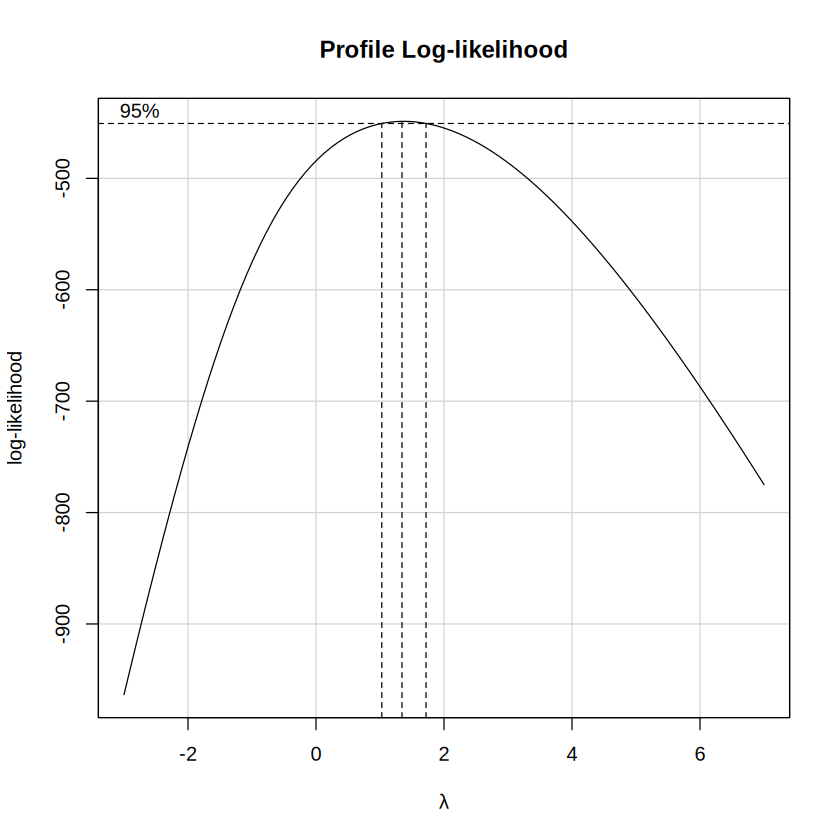

In [ ]:
boxCox(modelo, lam=seq(0, 2, 1/10)) # para alterar os intervalos

Nesse caso, o gráfico está indicando que não há necessidade de transformação dos dados, pois o intervalo está próximo do valor 1.

## Teste para checar autocorrelação entre os resíduos


In [ ]:
durbinWatsonTest(modelo)


 lag Autocorrelation D-W Statistic p-value
   1       0.6066108     0.7175647       0
 Alternative hypothesis: rho != 0

## Teste para checar outliers


In [ ]:
outlierTest(modelo)


     rstudent unadjusted p-value Bonferroni p
191 -3.869142         0.00015001     0.028951
192 -3.734764         0.00024829     0.047919

## Tabela de Análise de Variância


In [ ]:
anova(modelo)

#require(EnvStats)
#anovaPE(modelo) # nesse caso a anova inclui o teste de falta de ajuste (APENAS NO CASO DE DADOS COM MEDIDAS REPETIDAS PARA CADA x)

SQR <- sum((preditos-mean(y))^2); SQR  # soma de quadrados regressão
SQRes <- sum((y-preditos)^2); SQRes    # soma de quadrados dos erros
SQT <- sum((y-mean(y))^2); SQT         # soma de quadrados total

#soma de quadrados do erro puro (SQEPuro) = desvios ao quadrado dos valores de y com relação aos valores médios de y para cada x
#soma de quadrados de falta de ajuste = SqRes - SQEPuro


,Df,Sum Sq,Mean Sq,F value,Pr(>F)
,<int>,<dbl>,<dbl>,<dbl>,<dbl>
x_trans,1,77.11501,77.1150113,137.4975,2.862683e-24
Residuals,191,107.12170,0.5608466,NA,NA


[1] 77.11501

[1] 107.1217

[1] 184.2367

* $QMResiduo = 0,5609$
* desvio-padrão dos erros: $σ̂ = √0,5609 ≈ 0,749.$

## Intervalos de confiança para $\beta_0$ e $\beta_1$


In [ ]:
require(MASS)
confint(modelo) # IC 95% de confiança para os parâmetros beta0 e beta1

#### ou (obtencao passo a passo)
# intervalos de confianca para beta0, beta1
modelo <- lm(y~x)   # ajuste linear
summary(modelo)

coef=summary(modelo)$coefficients[1,1] ; coef
err=summary(modelo)$coefficients[1,2] ; err
coef + c(-1,1)*err*qt(0.975, (length(y)-2))  # intervalos de confiança para beta0

coef=summary(modelo)$coefficients[2,1] ; coef
err=summary(modelo)$coefficients[2,2] ; err
coef + c(-1,1)*err*qt(0.975, (length(y)-2))  # intervalos de confiança para beta1

confint(modelo)


,2.5 %,97.5 %
(Intercept),-2.0382482,-0.3997908
x_trans,0.4044147,0.5679858



Call:
lm(formula = y ~ x)

Residuals:
    Min      1Q  Median      3Q     Max 
-2.7841 -0.3507  0.1305  0.5423  1.5687 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept) -1.21902    0.41533  -2.935  0.00374 ** 
x            0.48620    0.04146  11.726  < 2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.7489 on 191 degrees of freedom
Multiple R-squared:  0.4186,	Adjusted R-squared:  0.4155 
F-statistic: 137.5 on 1 and 191 DF,  p-value: < 2.2e-16


[1] -1.219019

[1] 0.4153331

[1] -2.0382482 -0.3997908

[1] 0.4862002

[1] 0.04146367

[1] 0.4044147 0.5679858

,2.5 %,97.5 %
(Intercept),-2.0382482,-0.3997908
x,0.4044147,0.5679858


O intervalo para $β₁$ não contém zero, confirmando significância.

## Previsão para a média ou para uma observação futura e respectivos intervalos de confiança


x
<dbl>
5
6
7


,fit,lwr,upr
1,1.211982,-0.3229605,2.746924
2,1.698182,0.1826765,3.213687
3,2.184382,0.6841011,3.684663


,fit,lwr,upr
1,1.211982,0.7948313,1.629132
2,1.698182,1.3594734,2.036890
3,2.184382,1.9220653,2.446699


,fit,lwr,upr
1,1.211982,-0.07425897,2.498222
2,1.698182,0.42822881,2.968135
3,2.184382,0.92718662,3.441578


,fit,lwr,upr
1,1.211982,0.8624208,1.561543
2,1.698182,1.4143532,1.982011
3,2.184382,1.9645676,2.404197


[1]  7.629490  7.700885  7.772279  7.843674  7.915069  7.986464  8.057858
  [8]  8.129253  8.200648  8.272043  8.343437  8.414832  8.486227  8.557622
 [15]  8.629017  8.700411  8.771806  8.843201  8.914596  8.985990  9.057385
 [22]  9.128780  9.200175  9.271569  9.342964  9.414359  9.485754  9.557148
 [29]  9.628543  9.699938  9.771333  9.842727  9.914122  9.985517 10.056912
 [36] 10.128306 10.199701 10.271096 10.342491 10.413885 10.485280 10.556675
 [43] 10.628070 10.699464 10.770859 10.842254 10.913649 10.985043 11.056438
 [50] 11.127833 11.199228 11.270623 11.342017 11.413412 11.484807 11.556202
 [57] 11.627596 11.698991 11.770386 11.841781 11.913175 11.984570 12.055965
 [64] 12.127360 12.198754 12.270149 12.341544 12.412939 12.484333 12.555728
 [71] 12.627123 12.698518 12.769912 12.841307 12.912702 12.984097 13.055491
 [78] 13.126886 13.198281 13.269676 13.341070 13.412465 13.483860 13.555255
 [85] 13.626650 13.698044 13.769439 13.840834 13.912229 13.983623 14.055018
 [92] 14.126413 14.197808 14.269202 14.340597 14.411992 14.483387 14.554781
 [99] 14.626176 14.697571

,fit,lwr,upr
1,2.490440,0.9975229,3.983358
2,2.525152,1.0329603,4.017345
3,2.559865,1.0683753,4.051354
4,2.594577,1.1037677,4.085386
5,2.629289,1.1391375,4.119440
6,2.664001,1.1744847,4.153517
7,2.698713,1.2098093,4.187617
8,2.733425,1.2451113,4.221739
9,2.768138,1.2803905,4.255884
10,2.802850,1.3156471,4.290052


,fit,lwr,upr
1,2.490440,2.274178,2.706702
2,2.525152,2.313955,2.736350
3,2.559865,2.353692,2.766038
4,2.594577,2.393384,2.795770
5,2.629289,2.433029,2.825549
6,2.664001,2.472623,2.855380
7,2.698713,2.512161,2.885265
8,2.733425,2.551641,2.915210
9,2.768138,2.591056,2.945219
10,2.802850,2.630402,2.975297


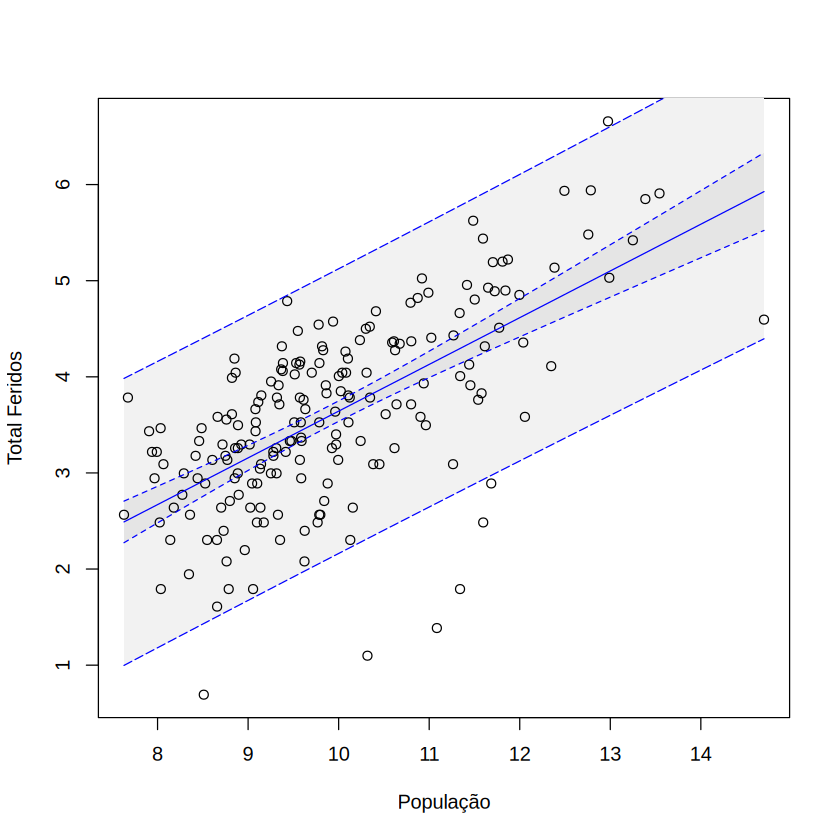

In [ ]:
#criar um vetor com as novas observações - nesse caso foi criado um vetor contendo os valores 5, 6 e 7 comerciais
novos_x <- data.frame(x = seq(5, 7, 1)) ; novos_x
modelo <- lm(y~x)

int_conf_nova_obs <- predict(modelo, novos_x, interval="prediction")  # intervalo de confiança 95% para novas obs (5 6 e 7 comerciais)
int_conf_nova_obs
int_conf_media <- predict(modelo, novos_x, interval="confidence")  # intervalo de confiança 95% para as médias (5 6 e 7 comerciais)
int_conf_media

# exemplo considerando outro nivel de confiança
int_conf_nova_obs <- predict(modelo, novos_x, level = 0.90, interval="prediction")  # intervalo de confiança 95% para novas obs (5 6 e 7 comerciais)
int_conf_nova_obs
int_conf_media <- predict(modelo, novos_x, level = 0.90, interval="confidence")   # intervalo de confiança 95% para as médias (5 6 e 7 comerciais)
int_conf_media

## Diagrama de dispersão com bandas de confiança para as médias e para novas observações

novos_x <- seq(min(x), max(x), length.out=100) ; novos_x

int_conf_nova_obs <- predict(modelo, newdata = data.frame(x=novos_x), interval="prediction")  # intervalo de confiança 95% para novas obs (5 6 e 7 comerciais)
int_conf_nova_obs
int_conf_media <- predict(modelo, newdata = data.frame(x=novos_x), interval="confidence")  # intervalo de confiança 95% para as médias (5 6 e 7 comerciais)
int_conf_media

# gráfico
par(mfrow=c(1,1))
plot(y ~ x, type = 'n', xlab="População", ylab="Total Feridos" )
polygon(c(rev(novos_x), novos_x), c(rev(int_conf_nova_obs[ ,3]), int_conf_nova_obs[ ,2]), col = 'grey95',  border = NA)   #acrescentar bandas para novas observa??es
polygon(c(rev(novos_x), novos_x), c(rev(int_conf_media[ ,3]), int_conf_media[ ,2]), col = 'grey90',  border = NA) #acrescentar bandas para as médias
points(x, y, type = 'p')
# acrescenta curva
lines(novos_x, int_conf_nova_obs[ ,1], col="blue")
lines(novos_x, int_conf_nova_obs[ ,2], col="blue", lty = 5)
lines(novos_x, int_conf_nova_obs[ ,3], col="blue", lty = 5)  #lty = 'dashed'

#lines(novos_x, int_conf_media[ ,1], col="blue")
lines(novos_x, int_conf_media[ ,2], col="blue", lty = 'dashed')
lines(novos_x, int_conf_media[ ,3], col="blue", lty = 'dashed')  #lty = 'dashed'


## Análise de influência

Uma observação influente é aquela cuja omissão do conjunto de dados resulta em grandes mudanças em certos aspectos do modelo.


 [1] add1                          addterm                      
 [3] alias                         anova                        
 [5] Anova                         avPlot                       
 [7] avPlot3d                      Boot                         
 [9] bootCase                      boxcox                       
[11] boxCox                        brief                        
[13] case.names                    ceresPlot                    
[15] coerce                        confidenceEllipse            
[17] confint                       Confint                      
[19] cooks.distance                crPlot                       
[21] crPlot3d                      deltaMethod                  
[23] deviance                      dfbeta                       
[25] dfbetaPlots                   dfbetas                      
[27] dfbetasPlots                  dffits                       
[29] drop1                         dropterm                     
[31] dummy.coef          

Potentially influential observations of
	 lm(formula = y ~ x) :

    dfb.1_ dfb.x dffit   cov.r   cook.d hat    
1   -0.35   0.37  0.40_*  1.00    0.08   0.03_*
4   -0.14   0.15  0.16    1.05_*  0.01   0.05_*
5   -0.14   0.15  0.16    1.05_*  0.01   0.04_*
7   -0.10   0.11  0.12    1.04_*  0.01   0.03  
9   -0.05   0.05  0.05    1.05_*  0.00   0.04_*
13  -0.06   0.06  0.07    1.03_*  0.00   0.02  
14   0.01  -0.02 -0.02    1.05_*  0.00   0.03_*
28   0.49  -0.51 -0.53_*  1.05_*  0.14   0.07_*
165  0.01  -0.01  0.01    1.03_*  0.00   0.02  
170  0.22  -0.25 -0.31_*  0.95_*  0.05   0.01  
186  0.24  -0.27 -0.37_*  0.90_*  0.06   0.01  
191  0.21  -0.25 -0.37_*  0.88_*  0.07   0.01  
192  0.04  -0.08 -0.28    0.88_*  0.04   0.01  
193 -0.27   0.24 -0.33_*  0.93_*  0.05   0.01  


[1] 193

[1] 2

[1] 0.02072539

,(Intercept),x
1,-0.345,0.369
2,-0.192,0.205
3,-0.195,0.210
4,-0.143,0.151
5,-0.140,0.149
6,-0.130,0.147
7,-0.100,0.107
8,-0.113,0.127
9,-0.047,0.050
10,-0.088,0.097


... (2 outputs left out)

[1] 0.3069867

1      2      3      4      5      6      7      8      9     10     11 
 0.401  0.226  0.236  0.161  0.159  0.192  0.118  0.162  0.054  0.117  0.116 
    12     13     14     15     16     17     18     19     20     21     22 
 0.119  0.070 -0.017  0.114  0.092  0.078  0.062  0.068  0.094  0.044  0.090 
    23     24     25     26     27     28     29     30     31     32     33 
 0.066  0.148  0.086  0.087  0.053 -0.529  0.093  0.098  0.072  0.001  0.071 
    34     35     36     37     38     39     40     41     42     43     44 
 0.106  0.024  0.034  0.062  0.047  0.039 -0.052  0.046  0.041  0.074 -0.018 
    45     46     47     48     49     50     51     52     53     54     55 
 0.103  0.069  0.036  0.057  0.048  0.140  0.072  0.084  0.059  0.074  0.070 
    56     57     58     59     60     61     62     63     64     65     66 
-0.032 -0.140  0.078  0.075  0.120  0.037  0.053  0.035  0.025  0.063 -0.041 
    67     68     69     70     71     72     73     74     75     76     77 
 0.035  0.117  0.073 -0.021 -0.066  0.033  0.063  0.019  0.024 -0.091  0.065 
    78     79     80     81     82     83     84     85     86     87     88 
 0.011  0.008 -0.003  0.035  0.252  0.050 -0.098  0.030  0.060 -0.037 -0.026 
    89     90     91     92     93     94     95     96     97     98     99 
 0.041  0.020  0.054  0.001 -0.030  0.069 -0.200  0.080 -0.060  0.067  0.038 
   100    101    102    103    104    105    106    107    108    109    110 
 0.009  0.012 -0.016 -0.001  0.049 -0.076  0.081  0.135  0.147  0.027 -0.022 
   111    112    113    114    115    116    117    118    119    120    121 
-0.007 -0.011 -0.006 -0.043 -0.005  0.064  0.015  0.037  0.021 -0.032 -0.005 
   122    123    124    125    126    127    128    129    130    131    132 
-0.075  0.019 -0.034  0.021 -0.008  0.097  0.103 -0.015  0.019 -0.012  0.045 
   133    134    135    136    137    138    139    140    141    142    143 
 0.012  0.024 -0.030 -0.049 -0.080 -0.015 -0.163 -0.075  0.066 -0.020 -0.034 
   144    145    146    147    148    149    150    151    152    153    154 
 0.029 -0.013 -0.031  0.051 -0.050  0.009 -0.018 -0.034 -0.036 -0.067 -0.005 
   155    156    157    158    159    160    161    162    163    164    165 
-0.260 -0.005 -0.041 -0.045 -0.083 -0.066 -0.106 -0.019 -0.050 -0.062  0.015 
   166    167    168    169    170    171    172    173    174    175    176 
-0.095 -0.080 -0.043 -0.095 -0.311 -0.085 -0.083 -0.034 -0.102 -0.106 -0.083 
   177    178    179    180    181    182    183    184    185    186    187 
-0.072 -0.093 -0.109 -0.090 -0.138 -0.114 -0.138 -0.126 -0.137 -0.369 -0.164 
   188    189    190    191    192    193 
-0.155 -0.164 -0.189 -0.374 -0.281 -0.328

[1] 0.6956687

1     2     3     4     5     6     7     8     9    10    11    12    13 
0.079 0.025 0.028 0.013 0.013 0.018 0.007 0.013 0.001 0.007 0.007 0.007 0.002 
   14    15    16    17    18    19    20    21    22    23    24    25    26 
0.000 0.006 0.004 0.003 0.002 0.002 0.004 0.001 0.004 0.002 0.011 0.004 0.004 
   27    28    29    30    31    32    33    34    35    36    37    38    39 
0.001 0.138 0.004 0.005 0.003 0.000 0.003 0.006 0.000 0.001 0.002 0.001 0.001 
   40    41    42    43    44    45    46    47    48    49    50    51    52 
0.001 0.001 0.001 0.003 0.000 0.005 0.002 0.001 0.002 0.001 0.010 0.003 0.004 
   53    54    55    56    57    58    59    60    61    62    63    64    65 
0.002 0.003 0.002 0.001 0.010 0.003 0.003 0.007 0.001 0.001 0.001 0.000 0.002 
   66    67    68    69    70    71    72    73    74    75    76    77    78 
0.001 0.001 0.007 0.003 0.000 0.002 0.001 0.002 0.000 0.000 0.004 0.002 0.000 
   79    80    81    82    83    84    85    86    87    88    89    90    91 
0.000 0.000 0.001 0.031 0.001 0.005 0.000 0.002 0.001 0.000 0.001 0.000 0.001 
   92    93    94    95    96    97    98    99   100   101   102   103   104 
0.000 0.000 0.002 0.020 0.003 0.002 0.002 0.001 0.000 0.000 0.000 0.000 0.001 
  105   106   107   108   109   110   111   112   113   114   115   116   117 
0.003 0.003 0.009 0.011 0.000 0.000 0.000 0.000 0.000 0.001 0.000 0.002 0.000 
  118   119   120   121   122   123   124   125   126   127   128   129   130 
0.001 0.000 0.001 0.000 0.003 0.000 0.001 0.000 0.000 0.005 0.005 0.000 0.000 
  131   132   133   134   135   136   137   138   139   140   141   142   143 
0.000 0.001 0.000 0.000 0.000 0.001 0.003 0.000 0.013 0.003 0.002 0.000 0.001 
  144   145   146   147   148   149   150   151   152   153   154   155   156 
0.000 0.000 0.000 0.001 0.001 0.000 0.000 0.001 0.001 0.002 0.000 0.033 0.000 
  157   158   159   160   161   162   163   164   165   166   167   168   169 
0.001 0.001 0.003 0.002 0.006 0.000 0.001 0.002 0.000 0.004 0.003 0.001 0.005 
  170   171   172   173   174   175   176   177   178   179   180   181   182 
0.047 0.004 0.003 0.001 0.005 0.006 0.003 0.003 0.004 0.006 0.004 0.009 0.006 
  183   184   185   186   187   188   189   190   191   192   193 
0.009 0.008 0.009 0.064 0.013 0.012 0.013 0.018 0.065 0.037 0.051

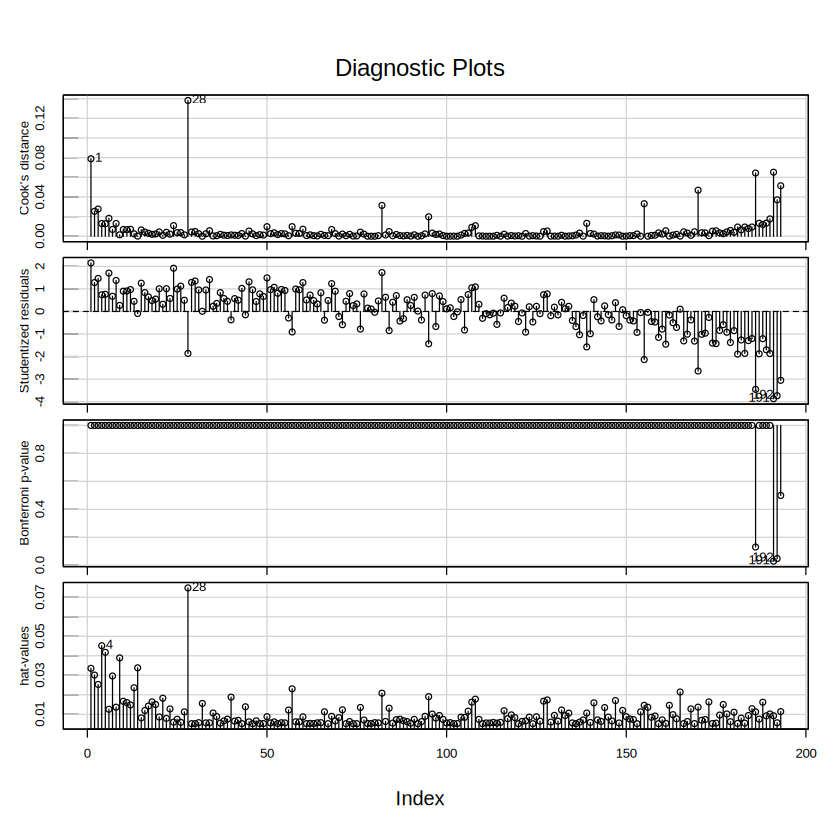

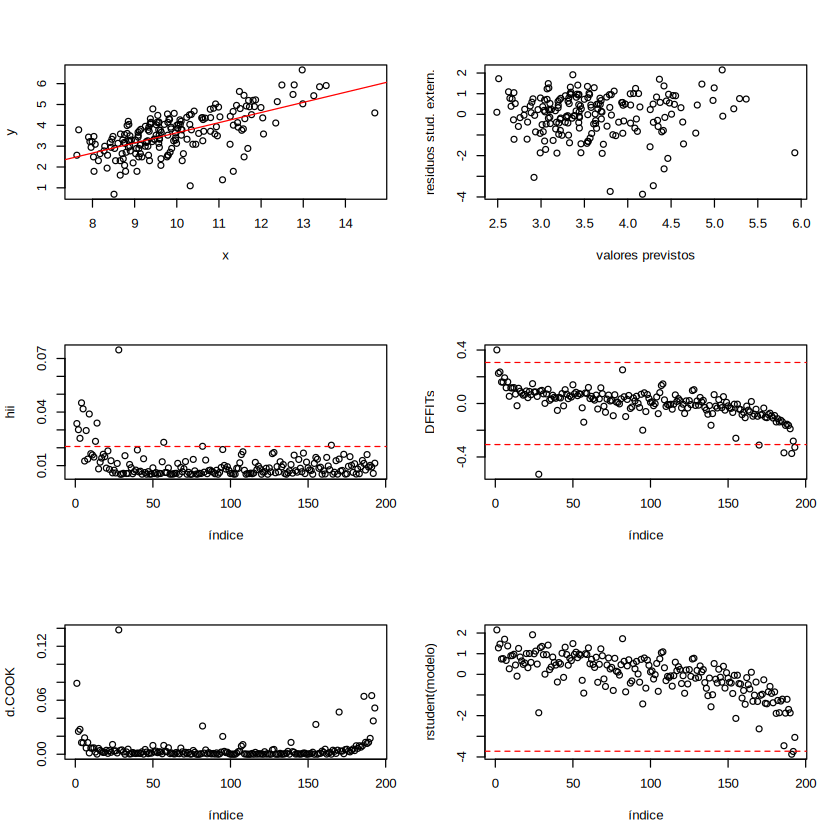

In [ ]:
methods(class="lm")  #para ver o que está disponível em lm

#Para realizar a análise de pontos influentes
inf <- influence.measures(modelo)
summary(inf)
par(mfrow = c(1, 1))
car::infIndexPlot(modelo)

#passo a passo realizar a análise de pontos influentes

#elementos hii da diagonal da matriz de projeção H
hii <- hatvalues(modelo)
# ou passo a passo a partir da matriz H
#H<-X%*%solve(t(X)%*%X)%*%t(X);H
#diag_H <- diag(H); diag_H
# para obter limite para deteção de ponto influente
n<-length(y);n
p<-ncol(model.matrix(lm(y~x)));p
pad_lev<-2*p/n;pad_lev

# DFBeta -  detecta observação influente nas estimativas dos parâmetros
DBETAs <-dfbetas(modelo)
DBETAs <- round(DBETAs,3) #arredondando em 3 casas decimais
DBETAs

# DFFits - detecta observação influente nos y ajustados
pad_Fit<-3*sqrt(p/(n-p));pad_Fit
t(p/(n-p));pad_Fit
DFFITs <- dffits(modelo)
round(DFFITs,3)

#distância de Cook (Di)
# Di - dist?ncia de Cooks - afastamento do vetor de estimativas de y com a retirada da obs i
pad_Cook<-qf(0.5,p,n-p,lower.tail=F); pad_Cook
d.COOK <- cooks.distance(modelo)
round(d.COOK,3)

#gráficos: 1) de Y vs X; 2) de rsei vs valores ajustados; 3) de índices para hii, DFFitS(i) e Di;

par(mfrow=c(3,2))
plot(y~x) #1)
#identify(x,y4)
abline(lm(y~x), col="red") # reta de regressão
#locator()
plot(rstudent(modelo)~ predict(modelo), ylab = "residuos stud. extern.", xlab="valores previstos") #2)
#locator()
plot(hii, xlab = "índice") #3)
abline(h=2*p/n, col="red",lty=2)
plot(DFFITs, xlab = "índice") #4)
abline(h=c(-(3*sqrt(p/(n-p))),(3*sqrt(p/(n-p)))), col="red",lty=2)
#plot(abs(dffits(m1)))
#abline(3*sqrt(m1$rank/m1$df.residual),0,lty=2)
plot(d.COOK, xlab = "índice") #5)
abline(h=c(-qf(0.5,p,n-p,lower.tail=F),qf(0.5,p,n-p,lower.tail=F)), col="red", lty=2)
plot(rstudent(modelo), xlab = "índice")
abline(h=c(-qt((1-(0.05/(2*n))),n-p-1),qt((1-(0.05/(2*n))),n-p-1)), col="red", lty=2)

par(mfrow=c(1,1))


##  Análises adicionais de influência

Referência Apostila Modelos de Regressão de Demetrio e Zocchi

- Há pontos inconsistentes (não acompanham a tendência geral dos demais pontos)?
- Há pontos de alavanca? São bons ou ruins?
- Há pontos influentes? pag 177
- Há outliers?


[1] 8

[1] 2

[1] 0.5

,1,2,3,4,5,6,7,8,9,10,⋯,184,185,186,187,188,189,190,191,192,193
1,0.0335630628,0.0317909313,0.029071789,0.0388668422,0.0374106520,0.019674185,0.0315308719,0.020683185,3.612377e-02,0.023253288,⋯,-0.0057293314,-9.604475e-03,0.018319605,-2.999740e-03,-0.0125018679,-5.510021e-03,-0.0067057569,0.015933616,0.008782792,-0.0080776377
2,0.0317909313,0.0301294503,0.027580089,0.0367635470,0.0353982801,0.018769264,0.0298856288,0.019715263,3.419175e-02,0.022124891,⋯,-0.0050480774,-8.681260e-03,0.017499263,-2.488920e-03,-0.0113977422,-4.842460e-03,-0.0059635357,0.015262253,0.008557921,-0.0072497573
3,0.0290717889,0.0275800890,0.025291238,0.0335362701,0.0323105151,0.017380761,0.0273611828,0.018230092,3.122728e-02,0.020393488,⋯,-0.0040027675,-7.264687e-03,0.016240537,-1.705121e-03,-0.0097035818,-3.818162e-03,-0.0048246782,0.014232120,0.008212880,-0.0059794653
4,0.0388668422,0.0367635470,0.033536270,0.0451617554,0.0434334423,0.022382506,0.0364548895,0.023580062,4.190608e-02,0.026630448,⋯,-0.0077682438,-1.236755e-02,0.020774792,-4.528566e-03,-0.0158063853,-7.507950e-03,-0.0089271370,0.017942926,0.009455805,-0.0105553854
5,0.0374106520,0.0353982801,0.032310515,0.0434334423,0.0417798425,0.021638917,0.0351029656,0.022784704,4.031851e-02,0.025703225,⋯,-0.0072084460,-1.160893e-02,0.020100703,-4.108816e-03,-0.0148991066,-6.959404e-03,-0.0083172413,0.017391255,0.009271025,-0.0098751022
6,0.0196741848,0.0187692637,0.017380761,0.0223825064,0.0216389175,0.012581969,0.0186364670,0.013097205,2.098179e-02,0.014409602,⋯,-0.0003900811,-2.368884e-03,0.011890266,1.003757e-03,-0.0038484088,-2.780923e-04,-0.0008886830,0.010671885,0.007020389,-0.0015892201
7,0.0315308719,0.0298856288,0.027361183,0.0364548895,0.0351029656,0.018636467,0.0296441902,0.019573221,3.390823e-02,0.021959299,⋯,-0.0049481038,-8.545778e-03,0.017378878,-2.413957e-03,-0.0112357123,-4.744496e-03,-0.0058546151,0.015163731,0.008524921,-0.0071282663
8,0.0206831852,0.0197152629,0.018230092,0.0235800619,0.0227847039,0.013097205,0.0195732208,0.013648312,2.208182e-02,0.015052079,⋯,-0.0007779675,-2.894536e-03,0.012357346,7.129107e-04,-0.0044770660,-6.581818e-04,-0.0013112823,0.011054140,0.007148424,-0.0020605912
9,0.0361237748,0.0341917545,0.031227280,0.0419060824,0.0403185088,0.020981787,0.0339082315,0.022081823,3.891552e-02,0.024883811,⋯,-0.0067137365,-1.093851e-02,0.019504991,-3.737871e-03,-0.0140973183,-6.474639e-03,-0.0077782590,0.016903729,0.009107729,-0.0092739163
10,0.0232532884,0.0221248909,0.020393488,0.0266304482,0.0257032250,0.014409602,0.0219592992,0.015052079,2.488381e-02,0.016688582,⋯,-0.0017659828,-4.233464e-03,0.013547079,-2.792681e-05,-0.0060783676,-1.626337e-03,-0.0023877177,0.012027810,0.007474553,-0.0032612571


1     2     3     4     5     6     7     8     9    10    11    12    13 
0.034 0.030 0.025 0.045 0.042 0.013 0.030 0.014 0.039 0.017 0.016 0.015 0.024 
   14    15    16    17    18    19    20    21    22    23    24    25    26 
0.034 0.008 0.012 0.014 0.016 0.015 0.009 0.018 0.008 0.013 0.006 0.007 0.006 
   27    28    29    30    31    32    33    34    35    36    37    38    39 
0.011 0.075 0.005 0.005 0.006 0.016 0.006 0.006 0.011 0.009 0.005 0.007 0.008 
   40    41    42    43    44    45    46    47    48    49    50    51    52 
0.019 0.007 0.007 0.005 0.014 0.006 0.005 0.007 0.005 0.005 0.009 0.006 0.006 
   53    54    55    56    57    58    59    60    61    62    63    64    65 
0.005 0.006 0.006 0.012 0.023 0.006 0.006 0.009 0.005 0.005 0.005 0.006 0.006 
   66    67    68    69    70    71    72    73    74    75    76    77    78 
0.011 0.005 0.009 0.007 0.008 0.012 0.005 0.006 0.005 0.005 0.013 0.007 0.005 
   79    80    81    82    83    84    85    86    87    88    89    90    91 
0.005 0.006 0.006 0.021 0.006 0.013 0.005 0.007 0.007 0.007 0.006 0.005 0.007 
   92    93    94    95    96    97    98    99   100   101   102   103   104 
0.005 0.006 0.009 0.019 0.010 0.008 0.009 0.007 0.006 0.006 0.005 0.005 0.009 
  105   106   107   108   109   110   111   112   113   114   115   116   117 
0.008 0.012 0.016 0.018 0.007 0.005 0.006 0.006 0.006 0.005 0.006 0.012 0.008 
  118   119   120   121   122   123   124   125   126   127   128   129   130 
0.010 0.008 0.005 0.006 0.007 0.009 0.005 0.009 0.006 0.017 0.017 0.006 0.009 
  131   132   133   134   135   136   137   138   139   140   141   142   143 
0.006 0.012 0.009 0.011 0.006 0.005 0.006 0.007 0.011 0.006 0.016 0.007 0.006 
  144   145   146   147   148   149   150   151   152   153   154   155   156 
0.013 0.009 0.007 0.017 0.006 0.012 0.009 0.008 0.007 0.005 0.011 0.015 0.014 
  157   158   159   160   161   162   163   164   165   166   167   168   169 
0.008 0.009 0.005 0.007 0.005 0.015 0.010 0.008 0.021 0.005 0.006 0.013 0.005 
  170   171   172   173   174   175   176   177   178   179   180   181   182 
0.014 0.007 0.007 0.016 0.005 0.005 0.010 0.015 0.010 0.006 0.011 0.005 0.008 
  183   184   185   186   187   188   189   190   191   192   193 
0.005 0.009 0.013 0.011 0.008 0.016 0.009 0.010 0.009 0.006 0.011

Influence measures of
	 lm(formula = y ~ x) :

       dfb.1_     dfb.x     dffit cov.r   cook.d     hat inf
1   -3.45e-01  0.368581  0.400815 0.997 7.88e-02 0.03356   *
2   -1.92e-01  0.205450  0.225778 1.024 2.54e-02 0.03013    
3   -1.95e-01  0.210370  0.235920 1.014 2.77e-02 0.02529    
4   -1.43e-01  0.151447  0.160962 1.052 1.30e-02 0.04516   *
5   -1.40e-01  0.148968  0.159164 1.048 1.27e-02 0.04178   *
6   -1.30e-01  0.147144  0.191859 0.993 1.82e-02 0.01258    
7   -9.96e-02  0.106859  0.117633 1.036 6.94e-03 0.02964   *
8   -1.13e-01  0.127367  0.161708 1.004 1.30e-02 0.01365    
9   -4.73e-02  0.050325  0.054052 1.051 1.47e-03 0.03892   *
10  -8.80e-02  0.097317  0.117196 1.019 6.87e-03 0.01669    
11  -8.59e-02  0.095266  0.115870 1.018 6.72e-03 0.01599    
12  -8.60e-02  0.095929  0.118999 1.016 7.08e-03 0.01480    
13  -5.71e-02  0.061837  0.069993 1.033 2.46e-03 0.02361   *
14   1.44e-02 -0.015358 -0.016690 1.046 1.40e-04 0.03383   *
15  -5.65e-02  0.068854  0.113801 1.00

Potentially influential observations of
	 lm(formula = y ~ x) :

    dfb.1_ dfb.x dffit   cov.r   cook.d hat    
1   -0.35   0.37  0.40_*  1.00    0.08   0.03_*
4   -0.14   0.15  0.16    1.05_*  0.01   0.05_*
5   -0.14   0.15  0.16    1.05_*  0.01   0.04_*
7   -0.10   0.11  0.12    1.04_*  0.01   0.03  
9   -0.05   0.05  0.05    1.05_*  0.00   0.04_*
13  -0.06   0.06  0.07    1.03_*  0.00   0.02  
14   0.01  -0.02 -0.02    1.05_*  0.00   0.03_*
28   0.49  -0.51 -0.53_*  1.05_*  0.14   0.07_*
165  0.01  -0.01  0.01    1.03_*  0.00   0.02  
170  0.22  -0.25 -0.31_*  0.95_*  0.05   0.01  
186  0.24  -0.27 -0.37_*  0.90_*  0.06   0.01  
191  0.21  -0.25 -0.37_*  0.88_*  0.07   0.01  
192  0.04  -0.08 -0.28    0.88_*  0.04   0.01  
193 -0.27   0.24 -0.33_*  0.93_*  0.05   0.01  


     rstudent unadjusted p-value Bonferroni p
191 -3.869142         0.00015001     0.028951
192 -3.734764         0.00024829     0.047919

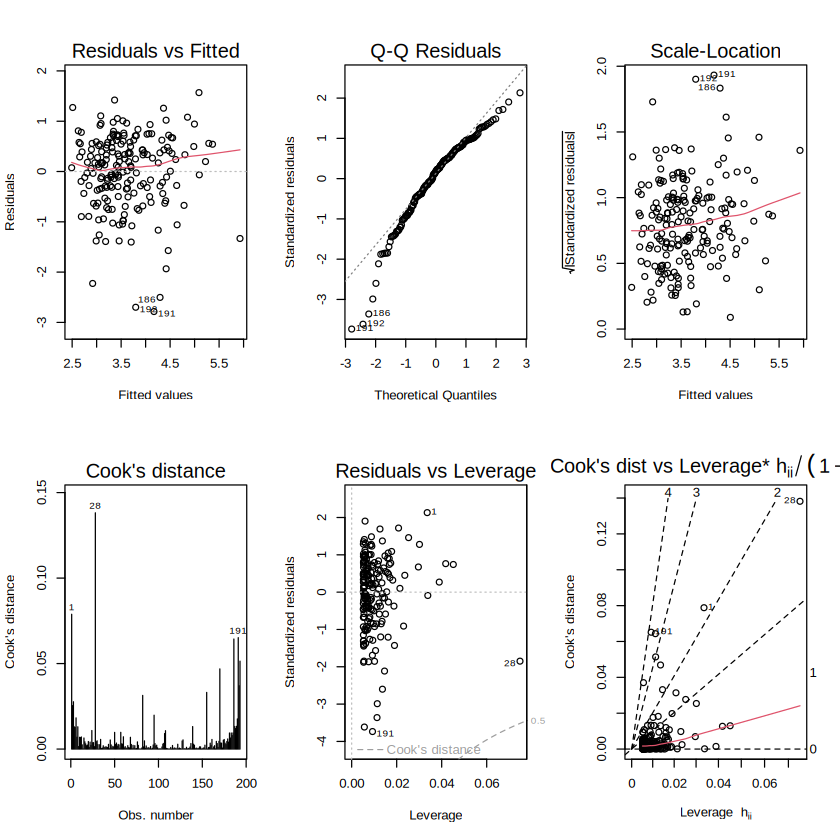

In [ ]:
# Pontos inconsistentes (pontos com valores absolutos de resíduos studentizados externamente maiores que t_alpha)
n=length(dados);n
p<-ncol(model.matrix(lm(y~x)));p
modelo<-lm(y~x)


# Pontos de alavanca - hii grande maior que pad_lev
# bom quando consistente
# ruim quando inconsistente
pad_lev<-2*p/n;pad_lev
X<-model.matrix(modelo)
H<-X%*%solve(t(X)%*%X)%*%t(X);H
round(diag(H),3)


# Pontos influentes
inf<-influence.measures(modelo); inf
summary(inf)

par(mfrow=c(2,3))
plot(modelo, which=1:6)
par(mfrow=c(1,1))

#Há outliers?
outlierTest(modelo)


## Conclusões

* Existe relação estatisticamente significativa entre o número de feridos em acidentes em rodovias federais em Minas Gerais (2025) e a população do município, após log–log ($p$ muito menor que $\alpha$, $R² = 0,42$).
* A elasticidade estimada é β̂₁ = 0,486 — bastante estável ($IC_{95} = [0,404; 0,568]$). A relação é (quase) linear: dobrar a população está associado a aproximadamente 40% a mais de feridos.
* As suposições de normalidade e variância constante dos resíduos não foram completamente atendidas.